# Time to Culture Conversion, Death and Loss to Follow-up in MDR/RR-TB — a survival & competing-risks analysis

**Author:** Fordrane Albert Okumu · **Tools:** Python (lifelines, pandas, statsmodels, scipy, matplotlib)
**Companion:** every key estimate is rebuilt independently in R (`survival` package) in [`R/mdr_tb_survival.R`](../R/mdr_tb_survival.R), which cross-checks its numbers against this notebook.

> ⚠️ **SIMULATED DATA — NOT REAL PATIENTS.** Every record in this notebook was generated by [`data/generate_data.py`](../data/generate_data.py) using a random-number generator and *assumed, illustrative* effect sizes. The data do **not** reproduce, approximate or derive from the data or findings of any real study, and **no real patient data are used**. Numbers here describe the simulation only and must not be quoted as evidence about TB in Kenya.

---

## 0. Why this analysis?

Multidrug- or rifampicin-resistant TB (MDR/RR-TB) needs longer, more toxic and more expensive treatment than drug-susceptible TB, and outcomes are worse. My earlier work looked at *who* develops drug resistance among presumptive MDR-TB patients in western Kenya (Okumu A, et al. *J Clin Tuberc Other Mycobact Dis.* 2024;37:100466). The natural next question for a programme is: **once patients are on MDR-TB treatment, how fast do they respond, and who dies or drops out before they do?**

Three outcomes matter most to a TB programme:

| Outcome | What it means | Why it matters |
|---|---|---|
| **Sputum culture conversion** | Two consecutive negative cultures taken ≥ 30 days apart; the conversion date is the date of the first negative sample | The main early marker that treatment is working and that the patient is no longer infectious |
| **Death** | Death from any cause | The worst outcome; MDR-TB mortality is high, especially with advanced HIV and undernutrition |
| **Loss to follow-up (LTFU)** | Treatment interrupted for ≥ 2 consecutive months | Drives further transmission and amplifies resistance |

All three are **time-to-event** outcomes: what matters is not only *whether* they happen but *when*. This notebook uses survival-analysis methods to answer that properly, and it explains each method for both a clinical and a data audience.

## 1. Research questions

**Primary (competing-risks) analysis.** Among adults starting MDR/RR-TB treatment:

1. What proportion achieve sputum culture conversion by 2, 6, 12 and 24 months, accounting for patients who die or are lost to follow-up *before* converting?
2. Which baseline factors are associated with the **rate** of culture conversion (cause-specific hazard ratios)?
3. Which baseline factors are associated with the rate of **death before conversion** and **LTFU before conversion**?

**Secondary (overall survival) analysis.**

4. What is the probability of survival at 6, 12 and 24 months after treatment start, and how does it differ by HIV/CD4 status, nutritional status, resistance pattern and regimen?
5. Which baseline factors are associated with all-cause mortality over 24 months?

**Methodological question.** How large is the error if a naive analysis ignores competing risks and reports 1 − Kaplan–Meier as the "probability of conversion"?

## 2. Why survival methods? A short primer for clinical and data readers

### 2.1 Censoring: incomplete follow-up is not missing data

Patients start treatment on different dates between January 2023 and December 2025, but the data are extracted on **30 June 2026**. A patient who started in November 2025 has only about 7 months of follow-up. If she has not converted yet, we don't know *whether* she will; we only know that her conversion time is **longer than 7 months**. Her record is **right-censored**.

Simple methods fail here:

* **"Proportion converted"** (converted ÷ enrolled) treats censored patients as failures and **underestimates** conversion, more so for recent enrolees.
* **Dropping censored patients** throws away information and biases the sample towards patients with long follow-up or early events.
* **Logistic regression** on "converted yes/no" ignores *when* events happened and how long each patient was observed.

**Survival methods use every patient for exactly as long as they were observed.** The key assumption is **non-informative censoring**: patients censored at a given time have the same future risk as those still under follow-up. Administrative censoring (the data cut-off) satisfies this almost by design; transfer-out usually does too.

### 2.2 Competing risks: when another event *prevents* the event of interest

A patient who **dies before converting** can never convert. A patient **lost to follow-up** can no longer be observed converting. These are **competing events**: they remove the patient from being at risk of the event of interest, *for good*.

The common mistake is to treat competing events as ordinary censoring and compute **1 − Kaplan–Meier**. That estimate answers a **hypothetical** question: *"what proportion would convert in a world where nobody could die or be lost?"* Because KM assumes censored patients would go on to behave like those still at risk, it effectively lets the dead "convert later". **1 − KM therefore overestimates the real-world cumulative incidence**, and the overestimate grows with the frequency of the competing events.

The correct estimate of *"what proportion of patients actually convert by time t"* is the **cumulative incidence function (CIF)**, estimated non-parametrically with the **Aalen–Johansen estimator**:

$$\text{CIF}_k(t) = \sum_{t_j \le t} \hat S(t_{j}^-)\,\frac{d_{kj}}{n_j}$$

where $\hat S(t_j^-)$ is the probability of being **event-free from all causes** just before $t_j$, $d_{kj}$ is the number of type-$k$ events at $t_j$ and $n_j$ the number at risk. The CIFs of all causes plus the all-cause event-free probability add up to 1, which 1 − KM curves don't.

### 2.3 Two kinds of hazard, two kinds of question

| | Cause-specific hazard (CSH) | Subdistribution hazard (Fine–Gray) |
|---|---|---|
| Risk set | Patients still event-free from **all** causes | Also keeps patients who already had a competing event "at risk" |
| Interpretation | **Rate** of the event among those still at risk: an *aetiological* question ("does cavitation slow conversion?") | Directly linked to the **CIF**: a *prognostic* question ("what is a patient's absolute probability of converting?") |
| Fitting | Ordinary Cox model; competing events are censored **at their event time** | Weighted Cox model (`cmprsk::crr`, `survival::finegray`) |

This analysis uses **cause-specific Cox models** because (i) our questions about drivers of conversion, death and LTFU are aetiological, (ii) cause-specific hazards for *all* causes together fully describe the competing-risks process, and (iii) the CIF itself is reported non-parametrically with Aalen–Johansen. A Fine–Gray model is not available in `lifelines` 0.30.3, so it is not used here; Section 13.1 explains when you would want one.

## 3. Setup

In [1]:
import warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from lifelines import KaplanMeierFitter, CoxPHFitter, AalenJohansenFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test, proportional_hazard_test
from lifelines.utils import k_fold_cross_validation
from lifelines.plotting import add_at_risk_counts

ROOT = Path.cwd().parent if Path.cwd().name == "python" else Path.cwd()
OUT = ROOT / "outputs" / "python"; OUT.mkdir(parents=True, exist_ok=True)
TEAL, AMBER, GREY, RED = "#0f766e", "#b45309", "#94a3b8", "#b91c1c"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 60)
CUTOFF = pd.Timestamp("2026-06-30")
MONTH = 30.4375                                  # days per month, for plotting and reporting
HORIZONS = {"2 months": 61, "6 months": 183, "12 months": 365, "24 months": 730}

class CoxPH(CoxPHFitter):
    # lifelines' Cox model with tighter Newton-Raphson convergence (defaults stop at ~1e-4 relative accuracy
    # in a few HRs), so the R cross-check compares methods rather than optimiser tolerances.
    def fit(self, *args, **kwargs):
        kwargs.setdefault("fit_options", {"precision": 1e-10, "r_precision": 1e-14})
        return super().fit(*args, **kwargs)

def log_ticks(ax, axis="x", ticks=(0.25, 0.5, 0.7, 1, 1.5, 2, 3, 5, 8)):
    # plain-number tick labels on a log-scaled axis (instead of 6x10^-1)
    lo, hi = (ax.get_xlim() if axis == "x" else ax.get_ylim())
    t = [v for v in ticks if lo <= v <= hi]
    setter = ax.set_xticks if axis == "x" else ax.set_yticks
    setter(t, [f"{v:g}" for v in t]); setter([], minor=True)

## 4. Load the data and the data dictionary

The file looks like a programme-register export: one row per patient, with **dates** rather than ready-made analysis times. Deriving the times ourselves is part of the job, and a common source of errors.

In [2]:
raw = pd.read_csv(ROOT / "data" / "mdr_tb_cohort_simulated.csv")
print(f"{len(raw):,} rows x {raw.shape[1]} columns | {raw.patient_id.nunique():,} unique patient IDs")
raw.head(3).T

1,204 rows x 23 columns | 1,200 unique patient IDs


,0,1,2
patient_id,DRTB-0239,DRTB-0147,DRTB-1094
county,Siaya,Busia,Kisumu
treatment_start_date,2023-01-01,2023-01-02,2023-01-02
age_years,38,75,36
sex,Male,Male,Male
hiv_status,Negative,Positive,Positive
cd4_count,NaN,361.0,402.0
on_art,NaN,Yes,Yes
bmi_kg_m2,21.9,19.8,16.4
diabetes,No,No,No


| Variable | Type | Description |
|---|---|---|
| `patient_id` | ID | Simulated register number |
| `county` | categorical | Kisumu, Siaya, Homa Bay, Migori, Kakamega, Busia |
| `treatment_start_date` | date | Start of MDR/RR-TB treatment = **time zero** for all analyses |
| `age_years`, `sex` | numeric, categorical | Demographics (adults ≥ 18 years) |
| `hiv_status` | categorical | Positive / Negative |
| `cd4_count` | numeric (cells/µL) | Baseline CD4, **HIV-positive only**; partly missing |
| `on_art` | categorical | On antiretroviral therapy at TB treatment start (HIV-positive only) |
| `bmi_kg_m2` | numeric | Body-mass index; < 18.5 = undernutrition; partly missing |
| `diabetes`, `current_smoker`, `previous_tb_treatment` | Yes/No | Comorbidity and history |
| `cavitary_disease` | Yes/No | Cavities on baseline chest X-ray |
| `baseline_smear_grade` | ordinal | Negative/scanty, 1+, 2+/3+ (bacillary load) |
| `resistance_pattern` | categorical | RR/MDR vs **pre-XDR** (additional fluoroquinolone resistance) |
| `regimen` | categorical | **Short all-oral** (6 months, BPaLM-like) vs **longer individualised** (18–20 months) |
| `dot_adherence_pct` | numeric (%) | Proportion of doses taken under directly observed therapy (DOT) during the first 2 weeks of treatment |
| `distance_to_clinic_km` | numeric | Distance from home to the treating clinic |
| `culture_conversion_date` | date | Date of the first of two consecutive negative cultures (blank if not observed) |
| `death_date`, `ltfu_date`, `transfer_out_date` | date | Date of the event, if it happened during follow-up |
| `last_followup_date` | date | Last date the patient's status is known: death, LTFU, transfer, 24 months, or the 30-Jun-2026 cut-off |

**A note on adherence.** Adherence is measured over the first two weeks of treatment, so strictly it is not a *baseline* variable. A patient who dies on day 5 has had less chance to accumulate adherence. In this simulation no conversions (cultures are monthly), 16 deaths and 9 LTFU events happen in the first 14 days (checked in Section 5), so the bias is small. In a real study, a **landmark analysis** starting the clock at day 14 would be the clean solution.

## 5. Data cleaning, derivation of analysis times, and data-quality checks

Every change is written to a cleaning log, the same audit-trail practice used in the companion TB drug-resistance repository and in multi-site trial data management.

In [3]:
log = []
d = raw.copy()

dup = d.duplicated()                                   # fully identical rows = double data entry
log.append(f"Removed {dup.sum()} exact duplicate records")
d = d.loc[~dup].copy()
assert d.patient_id.is_unique, "conflicting duplicate IDs need manual review"

bad_bmi = d.bmi_kg_m2.notna() & ~d.bmi_kg_m2.between(10, 60)
log.append(f"Set {bad_bmi.sum()} implausible BMI values to missing: {sorted(d.loc[bad_bmi, 'bmi_kg_m2'].tolist())}")
d.loc[bad_bmi, "bmi_kg_m2"] = np.nan

date_cols = ["treatment_start_date", "culture_conversion_date", "death_date", "ltfu_date",
             "transfer_out_date", "last_followup_date"]
for c in date_cols:
    d[c] = pd.to_datetime(d[c])

days = lambda c: (d[c] - d.treatment_start_date).dt.days
d["t_conv"], d["t_death"], d["t_ltfu"], d["t_transfer"], d["t_last"] = (
    days("culture_conversion_date"), days("death_date"), days("ltfu_date"), days("transfer_out_date"), days("last_followup_date"))

# Logical consistency checks: each must be zero in a clean register
checks = pd.Series({
    "event date before treatment start": int((d[["t_conv", "t_death", "t_ltfu", "t_transfer"]] < 0).sum().sum()),
    "conversion on/after last follow-up": int((d.t_conv >= d.t_last).sum()),
    "death/LTFU/transfer date != last follow-up": int(sum(((d[c].notna()) & (d[c] != d.t_last)).sum()
                                                          for c in ["t_death", "t_ltfu", "t_transfer"])),
    "more than one exit event recorded": int((d[["t_death", "t_ltfu", "t_transfer"]].notna().sum(axis=1) > 1).sum()),
    "last follow-up after data cut-off": int((d.last_followup_date > CUTOFF).sum()),
    "follow-up longer than 24 months": int((d.t_last > 730).sum()),
}, name="records failing")
display(checks.to_frame())
for line in log: print(line)

,records failing
event date before treatment start,0
conversion on/after last follow-up,0
death/LTFU/transfer date != last follow-up,0
more than one exit event recorded,0
last follow-up after data cut-off,0
follow-up longer than 24 months,0


Removed 4 exact duplicate records
Set 3 implausible BMI values to missing: [0.0, 98.0, 214.0]


**Interpretation:** the planted data-quality problems were found and fixed (exact duplicate records and impossible BMI values such as 0 or 214 kg/m²), and all logical date checks pass: no event before treatment start, at most one exit event per patient, and no follow-up beyond 24 months or the data cut-off.

### 5.1 Deriving the two outcome definitions

**Primary competing-risks outcome:** time from treatment start to the **first** of:

| Code | Event | Time |
|---|---|---|
| 1 | Culture conversion | `t_conv` |
| 2 | Death **before** conversion | `t_death` |
| 3 | LTFU **before** conversion | `t_ltfu` |
| 0 | Censored: transfer out, 24 months, or data cut-off without any of the above | `t_last` |

**Secondary overall-survival outcome:** time to death from any cause (before *or* after conversion), censored at LTFU, transfer out, 24 months or the cut-off. Patients lost to follow-up are censored at their LTFU date because their vital status afterwards is unknown. This is a real limitation: LTFU patients may have a higher risk of death than those who stay in care (informative censoring).

In [4]:
d["status"] = np.select([d.t_conv.notna(), d.t_death.notna(), d.t_ltfu.notna()], [1, 2, 3], 0)
d["time"] = np.where(d.status == 1, d.t_conv, d.t_last).astype(float)
d["os_time"] = d.t_last.astype(float)
d["died"] = d.t_death.notna().astype(int)
d["censor_reason"] = np.select([d.status > 0, d.t_transfer.notna(), d.t_last == 730], ["(event)", "transfer out", "completed 24 months"],
                               "administrative (data cut-off)")
EVENT = {0: "Censored", 1: "Culture conversion", 2: "Death before conversion", 3: "LTFU before conversion"}
d["status_label"] = d.status.map(EVENT)

summary = d.status_label.value_counts().reindex(EVENT.values()).rename("patients").to_frame()
summary["%"] = (100 * summary.patients / len(d)).round(1)
display(summary)
print(d.loc[d.status == 0, "censor_reason"].value_counts().to_string())
print(f"\nOverall survival: {d.died.sum()} deaths in total "
      f"({(d.died & (d.status == 1)).sum()} of them AFTER culture conversion); "
      f"{(d.died == 0).sum()} censored")
print(f"Events in the first 14 days (adherence measurement window): conversion {(d.time[d.status==1] <= 14).sum()}, "
      f"death {(d.time[d.status==2] <= 14).sum()}, LTFU {(d.time[d.status==3] <= 14).sum()}")

,patients,%
status_label,,
Censored,27,2.2
Culture conversion,987,82.2
Death before conversion,91,7.6
LTFU before conversion,95,7.9


censor_reason
administrative (data cut-off)    22
completed 24 months               3
transfer out                      2

Overall survival: 156 deaths in total (65 of them AFTER culture conversion); 1044 censored
Events in the first 14 days (adherence measurement window): conversion 0, death 16, LTFU 9


### 5.2 Visualising follow-up: why censoring happens

The plot below shows 40 randomly chosen patients on the **calendar** timeline (left) and on the **analysis** timeline, where everyone starts at time zero (right). Staggered enrolment and a fixed data cut-off mean that late enrolees are censored early. This is the situation survival methods are built for.

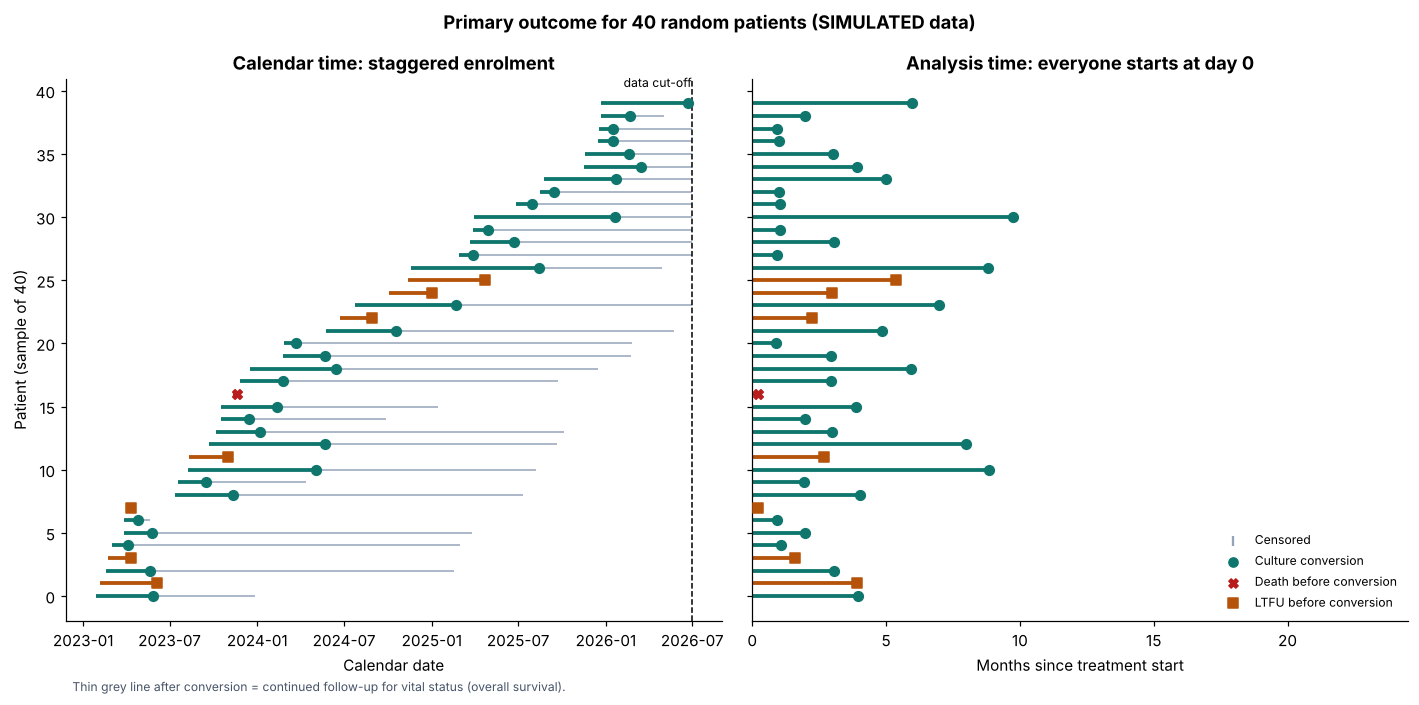

In [5]:
sample = d.sample(40, random_state=11).sort_values("treatment_start_date").reset_index(drop=True)
colors = {1: TEAL, 2: RED, 3: AMBER, 0: GREY}
markers = {1: "o", 2: "X", 3: "s", 0: "|"}
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), sharey=True)
for i, r in sample.iterrows():
    end_primary = r.treatment_start_date + pd.Timedelta(days=r.time)
    axes[0].hlines(i, r.treatment_start_date, r.last_followup_date, color=GREY, lw=1)
    axes[0].hlines(i, r.treatment_start_date, end_primary, color=colors[r.status] if r.status else GREY, lw=2.5)
    axes[0].scatter(end_primary, i, marker=markers[r.status], color=colors[r.status], s=40, zorder=3)
    axes[1].hlines(i, 0, r.time / MONTH, color=colors[r.status] if r.status else GREY, lw=2.5)
    axes[1].scatter(r.time / MONTH, i, marker=markers[r.status], color=colors[r.status], s=40, zorder=3)
axes[0].axvline(CUTOFF, color="black", ls="--", lw=1); axes[0].text(CUTOFF, 40.3, " data cut-off", fontsize=8, ha="right")
axes[0].set(title="Calendar time: staggered enrolment", xlabel="Calendar date", ylabel="Patient (sample of 40)")
axes[1].set(title="Analysis time: everyone starts at day 0", xlabel="Months since treatment start", xlim=(0, 24.5))
for k, lab in EVENT.items():
    axes[1].scatter([], [], marker=markers[k], color=colors[k], label=lab)
axes[1].legend(loc="lower right", fontsize=8, frameon=False)
axes[0].text(0.01, -0.13, "Thin grey line after conversion = continued follow-up for vital status (overall survival).",
             transform=axes[0].transAxes, fontsize=8, color="#475569")
fig.suptitle("Primary outcome for 40 random patients (SIMULATED data)", fontweight="bold")
fig.tight_layout(); fig.savefig(OUT / "01_follow_up_swimmer.png", dpi=150); plt.show()

### 5.3 Analysis variables

In [6]:
d["male"] = (d.sex == "Male").astype(int)
d["age10"] = d.age_years / 10
d["age_group"] = pd.cut(d.age_years, [17, 24, 34, 44, 54, 120], labels=["18-24", "25-34", "35-44", "45-54", "55+"])
d["hiv_pos"] = (d.hiv_status == "Positive").astype(int)
d["hiv_cd4"] = np.select([d.hiv_pos == 0, d.cd4_count >= 200, d.cd4_count < 200],
                         ["HIV-negative", "HIV+ CD4 ≥200", "HIV+ CD4 <200"], "HIV+ CD4 unknown")
d["no_art"] = ((d.hiv_pos == 1) & (d.on_art == "No")).astype(int)
d["undernutrition"] = np.where(d.bmi_kg_m2.isna(), np.nan, (d.bmi_kg_m2 < 18.5).astype(float))
yes = lambda c: (d[c] == "Yes").astype(int)
d["diabetes_y"], d["smoker"], d["prev_tb"], d["cavitary"] = (yes("diabetes"), yes("current_smoker"),
                                                            yes("previous_tb_treatment"), yes("cavitary_disease"))
d["pre_xdr"] = (d.resistance_pattern == "Pre-XDR").astype(int)
d["short_regimen"] = d.regimen.str.startswith("Short").astype(int)
d["adherence_def10"] = (90 - d.dot_adherence_pct) / 10       # +1 = 10 percentage points BELOW 90%
d["distance10"] = d.distance_to_clinic_km / 10
d["enrol_year"] = d.treatment_start_date.dt.year
print(d[["age_years", "bmi_kg_m2", "cd4_count", "dot_adherence_pct", "distance_to_clinic_km"]].describe().T.round(1))

                        count   mean    std   min    25%    50%    75%     max
age_years              1200.0   38.5   12.4  18.0   29.0   37.0   46.0    80.0
bmi_kg_m2              1148.0   19.6    2.6  12.5   17.9   19.6   21.4    27.7
cd4_count               292.0  333.8  264.9  39.0  158.8  246.0  424.0  1400.0
dot_adherence_pct      1200.0   87.2    9.3  40.0   82.0   89.0   94.0   100.0
distance_to_clinic_km  1200.0   14.0   10.1   1.0    6.9   11.4   17.9    99.4


### 5.4 Missing data: how much, why, and what to do about it

Missing data are handled **before** modelling, with an explicit, justified choice. Three standard options:

| Approach | How it works | When it is reasonable | Risk |
|---|---|---|---|
| **Complete-case analysis** | Drop anyone with a missing value | Little missingness; missingness unrelated to the outcome given the covariates | Loses power; biased if missingness depends on the outcome |
| **Missing-indicator category** | Add "unknown" as a level of a categorical variable | Missingness is clinically meaningful (e.g. "CD4 not done" reflects access to care) and the variable is a confounder of secondary interest | Can bias the *other* coefficients when data are missing at random; recognised as a pragmatic, not principled, method |
| **Simple imputation** (e.g. median) | Replace missing with a typical value | Very few missing values | Understates uncertainty; median imputation of a dichotomised variable pushes everyone into the "normal" group |
| **Multiple imputation** (MICE) | Impute several times from a model and pool | Gold standard under missing-at-random (MAR) | More complex; with survival outcomes the imputation model must include the event indicator and the Nelson–Aalen cumulative hazard |

First, look at the pattern.

In [7]:
miss = pd.DataFrame({
    "missing": [d.cd4_count[d.hiv_pos == 1].isna().sum(), d.bmi_kg_m2.isna().sum()],
    "denominator": [d.hiv_pos.sum(), len(d)]}, index=["CD4 count (HIV+ only)", "BMI (all patients)"])
miss["% missing"] = (100 * miss.missing / miss.denominator).round(1)
display(miss)
other = d.drop(columns=["cd4_count", "bmi_kg_m2", "undernutrition", "on_art", "culture_conversion_date", "death_date",
                        "ltfu_date", "transfer_out_date", "t_conv", "t_death", "t_ltfu", "t_transfer"]).isna().sum()
print("Other variables with any missing values:", other[other > 0].to_dict() or "none")

hiv = d[d.hiv_pos == 1].assign(cd4_missing=lambda x: x.cd4_count.isna().astype(int))
mw = stats.mannwhitneyu(hiv.distance_to_clinic_km[hiv.cd4_missing == 1], hiv.distance_to_clinic_km[hiv.cd4_missing == 0])
print(f"\nMedian distance to clinic, HIV+ with CD4 missing vs recorded: "
      f"{hiv.distance_to_clinic_km[hiv.cd4_missing == 1].median():.1f} vs {hiv.distance_to_clinic_km[hiv.cd4_missing == 0].median():.1f} km "
      f"(Mann-Whitney p = {mw.pvalue:.3f})")
m = smf.logit("cd4_missing ~ distance10 + age10 + male + C(county) + enrol_year", data=hiv).fit(disp=0)
print(f"Logistic model for CD4 missingness: OR per 10 km = {np.exp(m.params['distance10']):.2f} "
      f"(95% CI {np.exp(m.conf_int().loc['distance10', 0]):.2f}-{np.exp(m.conf_int().loc['distance10', 1]):.2f}), p = {m.pvalues['distance10']:.4f}")
bm = d.assign(bmi_missing=d.bmi_kg_m2.isna().astype(int))
print("BMI missing by primary outcome (%):", (100 * bm.groupby("status_label").bmi_missing.mean()).round(1).to_dict())

,missing,denominator,% missing
CD4 count (HIV+ only),121,413,29.3
BMI (all patients),52,1200,4.3


Other variables with any missing values: none

Median distance to clinic, HIV+ with CD4 missing vs recorded: 14.8 vs 9.9 km (Mann-Whitney p = 0.000)
Logistic model for CD4 missingness: OR per 10 km = 1.57 (95% CI 1.23-2.02), p = 0.0004
BMI missing by primary outcome (%): {'Censored': 3.7, 'Culture conversion': 4.6, 'Death before conversion': 3.3, 'LTFU before conversion': 3.2}


**Decision and justification:**

* **CD4 (missing for 29.3% of HIV-positive patients):** missingness is clearly **related to distance to clinic**. Median distance is 14.8 vs 9.9 km, and the odds of a missing CD4 rise by 57% per 10 km (OR 1.57, 95% CI 1.23–2.02). Patients living further away are less likely to have a result, so CD4 is not "missing completely at random". Dropping these patients would remove a sizeable share of the HIV-positive group, which is one of the highest-risk groups, and the remaining HIV-positive patients would over-represent those living close to the clinic. We therefore keep them with a **missing-indicator category, "HIV+ CD4 unknown"**, inside a combined HIV/CD4 variable. Clinically this is a sensible group: "CD4 not done" is itself a marker of weaker access to care. We check the cost of this choice with a **complete-case sensitivity analysis** in Section 12.
* **BMI (missing for 52 patients, 4.3%):** missingness is low and similar across outcomes (3.2–4.6%), so the regression models use **complete cases for BMI**. Median imputation was rejected because BMI is analysed as undernutrition (< 18.5), and imputing the median would put every missing patient into the "not undernourished" group, diluting the effect.
* **Descriptive survival curves** (Kaplan–Meier, Aalen–Johansen) use **all patients**, because they don't need BMI.
* **Not done here:** multiple imputation. It is the principled approach under MAR and is the recommended next step for a real analysis (stating the imputation model in the protocol).

In [8]:
model_df = d[d.undernutrition.notna()].copy()
log.append(f"Regression analysis set: {len(model_df):,} of {len(d):,} patients ({len(d) - len(model_df)} excluded for missing BMI)")
print(log[-1])
print(model_df.status_label.value_counts().to_string())

Regression analysis set: 1,148 of 1,200 patients (52 excluded for missing BMI)
status_label
Culture conversion         942
LTFU before conversion      92
Death before conversion     88
Censored                    26


## 6. Table 1 — baseline characteristics by HIV status (STROBE item 14a)

HIV is the most important clinical stratifier in MDR-TB care in western Kenya, so baseline characteristics are compared between HIV-positive and HIV-negative patients. Continuous variables are summarised as median (IQR) and compared with the Mann–Whitney U test (no normality assumption); categorical variables as n (%) with the χ² test (Fisher's exact test for 2×2 tables with any expected count < 5). Missing values are reported, never silently dropped. p-values here are **descriptive** (they show where the groups differ) and are not a test of any hypothesis about outcomes.

In [9]:
groups = {"HIV-negative": d[d.hiv_pos == 0], "HIV-positive": d[d.hiv_pos == 1]}
rows = []

def cont(var, label, fmt="{:.0f}", subset=None):
    data = {g: (x if subset is None else x[subset(x)])[var] for g, x in groups.items()}
    allv = pd.concat(data.values())
    s = lambda v: f"{fmt.format(v.median())} ({fmt.format(v.quantile(.25))}–{fmt.format(v.quantile(.75))})"
    p = stats.mannwhitneyu(*[v.dropna() for v in data.values()]).pvalue if all(v.notna().sum() for v in data.values()) else np.nan
    rows.append([label, "median (IQR)", s(allv.dropna())] + [s(v.dropna()) if v.notna().any() else "—" for v in data.values()]
                + [p])
    nm = allv.isna().sum()
    if nm:
        rows.append(["", "missing", f"{nm}"] + [f"{v.isna().sum()}" for v in data.values()] + [np.nan])

def cat(var, label, order=None, subset=None, show=None):
    # p-value from the full table of all levels; `show` lists the levels to print (e.g. only "Yes" for binary rows).
    # Percentages use patients with a known value as the denominator; missing counts are shown separately.
    data = {g: (x if subset is None else x[subset(x)])[var] for g, x in groups.items()}
    allv = pd.concat(data.values())
    levels = order or sorted(allv.dropna().unique())
    tab = pd.DataFrame({g: v.value_counts().reindex(levels, fill_value=0) for g, v in data.items()})
    tab = tab.loc[:, tab.sum() > 0]
    if tab.shape[1] < 2: p = np.nan
    elif tab.shape == (2, 2) and (stats.contingency.expected_freq(tab.values) < 5).any(): p = stats.fisher_exact(tab.values)[1]
    else: p = stats.chi2_contingency(tab.values, correction=False)[1]
    pct = lambda v, lev: f"{(v == lev).sum()} ({100 * (v == lev).sum() / v.notna().sum():.1f}%)" if v.notna().any() else "—"
    for i, lev in enumerate(show or levels):
        rows.append([label if i == 0 else "", lev, pct(allv, lev)] + [pct(v, lev) for v in data.values()]
                    + [p if i == 0 else np.nan])
    if allv.isna().sum():
        rows.append(["", "missing", f"{allv.isna().sum()}"] + [f"{v.isna().sum()}" for v in data.values()] + [np.nan])

cont("age_years", "Age, years")
cat("sex", "Sex", ["Female", "Male"])
cat("county", "County", ["Kisumu", "Siaya", "Homa Bay", "Migori", "Kakamega", "Busia"])
cat("enrol_year", "Year of treatment start", [2023, 2024, 2025])
cont("cd4_count", "CD4 count, cells/µL (HIV+)", subset=lambda x: x.hiv_pos == 1)
cat("on_art", "On ART at TB treatment start (HIV+)", ["Yes", "No"], subset=lambda x: x.hiv_pos == 1)
cont("bmi_kg_m2", "BMI, kg/m²", "{:.1f}")
cat("undernutrition", "Undernutrition (BMI < 18.5)", [1.0, 0.0], show=[1.0])
cat("diabetes", "Diabetes", ["Yes", "No"], show=["Yes"])
cat("current_smoker", "Current smoker", ["Yes", "No"], show=["Yes"])
cat("previous_tb_treatment", "Previous TB treatment", ["Yes", "No"], show=["Yes"])
cat("cavitary_disease", "Cavitary disease on X-ray", ["Yes", "No"], show=["Yes"])
cat("baseline_smear_grade", "Baseline smear grade", ["Negative/scanty", "1+", "2+/3+"])
cat("resistance_pattern", "Resistance pattern", ["RR/MDR", "Pre-XDR"])
cat("regimen", "Regimen", ["Short all-oral (6 mo)", "Longer individualised (18-20 mo)"])
cont("dot_adherence_pct", "DOT adherence, first 2 weeks (%)")
cont("distance_to_clinic_km", "Distance to clinic, km", "{:.1f}")

n = {g: len(x) for g, x in groups.items()}
table1 = pd.DataFrame(rows, columns=["Characteristic", "Level", f"Overall (n={len(d)})",
                                     f"HIV-negative (n={n['HIV-negative']})", f"HIV-positive (n={n['HIV-positive']})", "p-value"])
table1["p-value"] = table1["p-value"].map(lambda p: "" if pd.isna(p) else ("<0.001" if p < .001 else f"{p:.3f}"))
table1["Level"] = table1["Level"].replace({1.0: "Yes"})
table1.to_csv(OUT / "table1_baseline_by_hiv.csv", index=False)
table1

,Characteristic,Level,Overall (n=1200),HIV-negative (n=787),HIV-positive (n=413),p-value
0,"Age, years",median (IQR),37 (29–46),37 (29–45),38 (30–46),0.317
1,Sex,Female,441 (36.8%),251 (31.9%),190 (46.0%),<0.001
2,,Male,759 (63.2%),536 (68.1%),223 (54.0%),
3,County,Kisumu,309 (25.8%),189 (24.0%),120 (29.1%),0.269
4,,Siaya,195 (16.2%),134 (17.0%),61 (14.8%),
5,,Homa Bay,211 (17.6%),144 (18.3%),67 (16.2%),
6,,Migori,162 (13.5%),114 (14.5%),48 (11.6%),
7,,Kakamega,195 (16.2%),123 (15.6%),72 (17.4%),
8,,Busia,128 (10.7%),83 (10.5%),45 (10.9%),
9,Year of treatment start,2023,404 (33.7%),271 (34.4%),133 (32.2%),0.609


**Interpretation (Table 1):** 413 of 1,200 patients (34.4%) are HIV-positive. Compared with HIV-negative patients they are more often **female** (46.0% vs 31.9%), **thinner** (median BMI 18.9 vs 19.9 kg/m²; undernutrition 42.1% vs 28.5%), less often smokers (17.2% vs 25.9%) and less often have **cavitary disease** (40.9% vs 48.9%, p = 0.008). The last point is clinically familiar: advanced immunosuppression blunts the inflammatory response that creates cavities, so HIV-positive patients with low CD4 often present *without* cavities. Among HIV-positive patients the median CD4 is 246 cells/µL (IQR 159–424), CD4 is missing for 121 (29.3%), and 88.9% are already on ART.

The two groups are similar in age, county, year of treatment start, smear grade, resistance pattern, **regimen** (59.1% vs 57.4% on the short regimen) and early adherence. So differences in outcomes between HIV groups can't be explained by different treatment.

## 7. Follow-up and crude outcomes

Before any modelling, describe how long patients were followed. The **median follow-up** is estimated with the **reverse Kaplan–Meier** method: flip the event indicator so that *censoring* becomes the "event". This gives the follow-up patients *would* have had if nobody died, and is the STROBE-recommended way to report follow-up (the naive median of observed times is shortened by early deaths).

In [10]:
rkm = KaplanMeierFitter().fit(d.os_time, 1 - d.died)
print(f"Median potential follow-up (reverse KM): {rkm.median_survival_time_ / MONTH:.1f} months")
print(f"Median observed follow-up (all patients): {d.os_time.median() / MONTH:.1f} months | "
      f"total person-time: {d.os_time.sum() / 365.25:,.0f} person-years")
crude = pd.DataFrame({
    "events": [(d.status == k).sum() for k in (1, 2, 3)] + [d.died.sum()],
    "person-years at risk": [d.time.sum() / 365.25] * 3 + [d.os_time.sum() / 365.25]},
    index=["Culture conversion", "Death before conversion", "LTFU before conversion", "Death (any time)"])
crude["crude rate per 100 person-years"] = (100 * crude.events / crude["person-years at risk"]).round(1)
crude.round(1)

Median potential follow-up (reverse KM): 18.1 months
Median observed follow-up (all patients): 15.3 months | total person-time: 1,486 person-years


,events,person-years at risk,crude rate per 100 person-years
Culture conversion,987,402.4,245.3
Death before conversion,91,402.4,22.6
LTFU before conversion,95,402.4,23.6
Death (any time),156,1485.9,10.5


**Interpretation:** median potential follow-up is **18.1 months** (reverse KM), shorter than 24 months because patients who started in 2025 are administratively censored at the June 2026 cut-off. Together, the 1,200 patients contribute 1,486 person-years.

For the primary outcome, 987 patients (82.2%) converted, 91 (7.6%) died before converting, 95 (7.9%) were lost to follow-up before converting, and only 27 (2.2%) were censored without any of these events (22 at the data cut-off, 3 still culture-positive at 24 months, 2 transferred out). Of the 156 deaths over the full 24 months, **65 happened after culture conversion**: converting is not the end of the risk. The crude conversion rate (245 per 100 person-years) is high because the denominator is the short time *before* each patient's first event. Rates describe speed; proportions over time come from the CIF in Section 9.

## 8. Overall survival — Kaplan–Meier (secondary outcome)

For **all-cause death** there is no competing event (everyone eventually dies of *something*), so the Kaplan–Meier estimator is the right tool. The KM estimate at time $t$ is the product of conditional survival probabilities at each death time:

$$\hat S(t) = \prod_{t_j \le t}\left(1 - \frac{d_j}{n_j}\right)$$

95% confidence intervals use Greenwood's variance on the log(−log) scale (lifelines' default; R's `survfit(..., conf.type = "log-log")` gives identical intervals).

,time,survival,lower 95%,upper 95%
0,6 months,0.918,0.901,0.933
1,12 months,0.880,0.859,0.899
2,24 months,0.837,0.811,0.860


Median overall survival: not reached (survival stays above 50% for all 24 months)


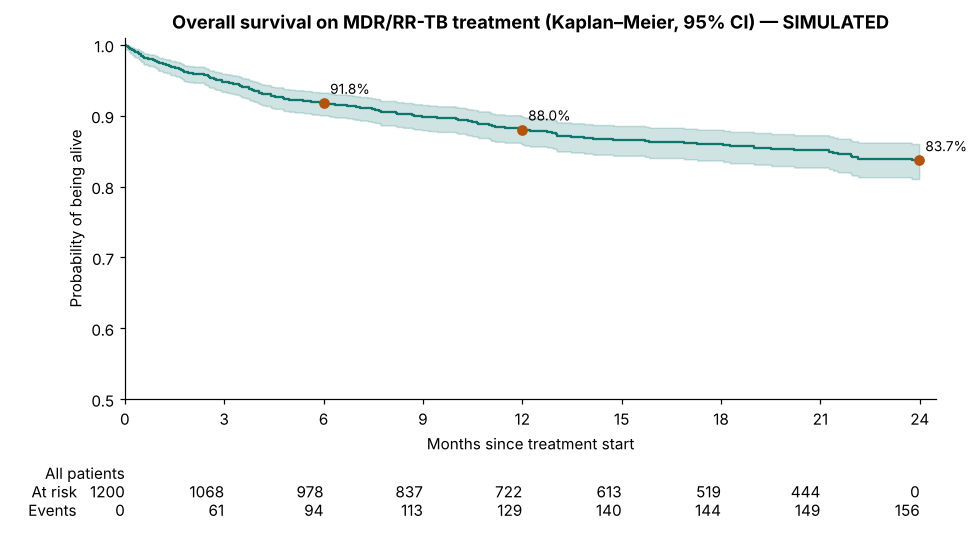

In [11]:
kmf = KaplanMeierFitter().fit(d.os_time, d.died, label="All patients")
def km_at(kmf, t):
    s = kmf.survival_function_at_times(t).iloc[0]
    ci = kmf.confidence_interval_survival_function_
    row = ci[ci.index <= t].iloc[-1]
    return s, row.iloc[0], row.iloc[1]
km_tab = pd.DataFrame([(lab, *km_at(kmf, t)) for lab, t in HORIZONS.items() if t > 61],
                      columns=["time", "survival", "lower 95%", "upper 95%"])
km_tab.to_csv(OUT / "km_overall_survival.csv", index=False)
display(km_tab.round(3))
med = kmf.median_survival_time_
print("Median overall survival:", "not reached (survival stays above 50% for all 24 months)" if np.isinf(med) else f"{med/MONTH:.1f} months")

fig, ax = plt.subplots(figsize=(9, 5.2))
kmf_m = KaplanMeierFitter().fit(d.os_time / MONTH, d.died, label="All patients")
kmf_m.plot_survival_function(ax=ax, color=TEAL, ci_alpha=.2)
for lab, t in list(HORIZONS.items())[1:]:
    s = kmf.survival_function_at_times(t).iloc[0]
    ax.scatter(t / MONTH, s, color=AMBER, zorder=3); ax.annotate(f"{s:.1%}", (t / MONTH, s), xytext=(4, 6), textcoords="offset points", fontsize=9)
ax.set(ylim=(0.5, 1.01), xlim=(0, 24.5), xlabel="Months since treatment start", ylabel="Probability of being alive",
       title="Overall survival on MDR/RR-TB treatment (Kaplan–Meier, 95% CI) — SIMULATED")
ax.set_xticks(range(0, 25, 3)); ax.get_legend().remove()
add_at_risk_counts(kmf_m, ax=ax, rows_to_show=["At risk", "Events"])
fig.tight_layout(); fig.savefig(OUT / "02_km_overall_survival.png", dpi=150); plt.show()

**Interpretation:** an estimated **91.8%** (95% CI 90.1–93.3) of patients are alive at 6 months, **88.0%** (85.9–89.9) at 12 months and **83.7%** (81.1–86.0) at 24 months. Put the other way, about 1 in 6 patients die within two years. Deaths are concentrated early: 61 of the 156 deaths (39%) occur in the first 3 months, which is the window for intensified clinical monitoring. **Median survival is not reached** because survival never drops to 50%. That's normal for a cohort like this, and is the reason survival is reported at fixed time points rather than as a median.

### 8.1 Survival by clinical group, with log-rank tests

The **log-rank test** compares whole survival curves: at each death time it compares the observed number of deaths in each group with the number expected if all groups shared the same hazard, then sums over time. It is most powerful when hazards are proportional and is a test of *any* difference, not a measure of its size (that comes from the Cox model). For more than two groups we use the k-group version (`multivariate_logrank_test`).

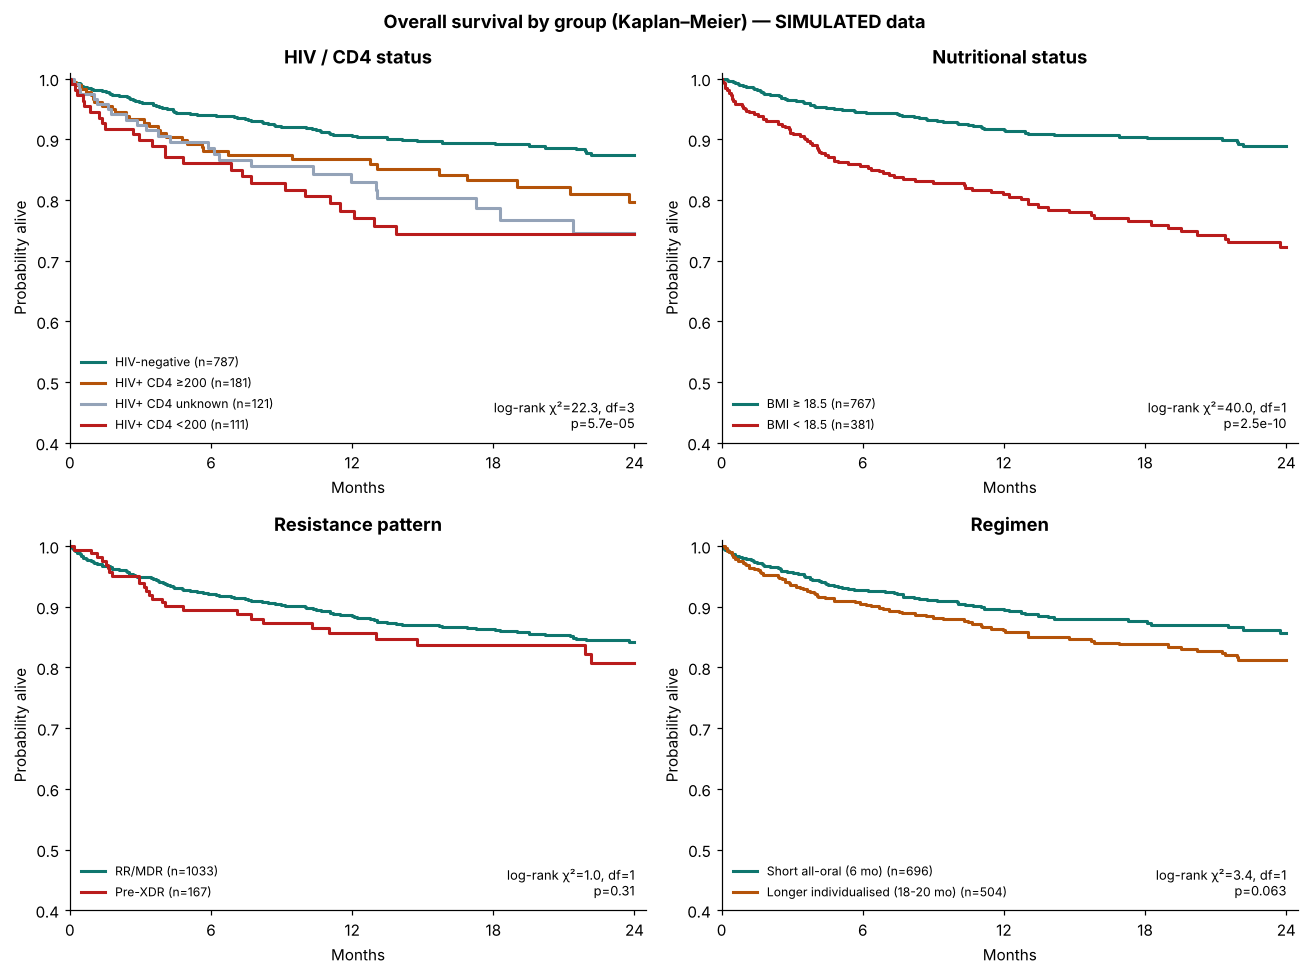

,comparison,chi2,df,p_value
0,HIV / CD4 status,22.2937,3,0.0001
1,Nutritional status,40.0157,1,0.0000
2,Resistance pattern,1.0466,1,0.3063
3,Regimen,3.4465,1,0.0634


,variable,group,n,deaths,S(6m),S(12m),S(24m)
0,hiv_cd4,HIV-negative,787,78,0.940,0.905,0.874
1,hiv_cd4,HIV+ CD4 ≥200,181,30,0.881,0.868,0.796
2,hiv_cd4,HIV+ CD4 unknown,121,23,0.886,0.830,0.746
3,hiv_cd4,HIV+ CD4 <200,111,25,0.860,0.783,0.743
4,undernutrition_lbl,BMI ≥ 18.5,767,68,0.945,0.915,0.889
5,undernutrition_lbl,BMI < 18.5,381,83,0.856,0.809,0.723
6,resistance_pattern,RR/MDR,1033,130,0.922,0.884,0.842
7,resistance_pattern,Pre-XDR,167,26,0.895,0.857,0.807
8,regimen,Short all-oral (6 mo),696,77,0.927,0.895,0.857
9,regimen,Longer individualised (18-20 mo),504,79,0.905,0.861,0.813


In [12]:
def km_group_plot(ax, var, order, palette, title):
    for lev, col in zip(order, palette):
        m = d[var] == lev
        KaplanMeierFitter().fit(d.os_time[m] / MONTH, d.died[m], label=f"{lev} (n={m.sum()})").plot_survival_function(
            ax=ax, color=col, ci_show=False, lw=2)
    sub = d[d[var].isin(order)]
    res = multivariate_logrank_test(sub.os_time, sub[var], sub.died)
    ax.set(title=title, xlabel="Months", ylabel="Probability alive", ylim=(0.4, 1.01), xlim=(0, 24.5))
    ax.set_xticks(range(0, 25, 6)); ax.legend(fontsize=8, frameon=False, loc="lower left")
    ax.text(.98, .04, f"log-rank χ²={res.test_statistic:.1f}, df={len(order)-1}\np={res.p_value:.2g}", transform=ax.transAxes,
            ha="right", fontsize=8.5)
    return {"comparison": title, "chi2": res.test_statistic, "df": len(order) - 1, "p_value": res.p_value}

d["undernutrition_lbl"] = d.undernutrition.map({1.0: "BMI < 18.5", 0.0: "BMI ≥ 18.5"})
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
lr = [km_group_plot(axes[0, 0], "hiv_cd4", ["HIV-negative", "HIV+ CD4 ≥200", "HIV+ CD4 unknown", "HIV+ CD4 <200"],
                    [TEAL, AMBER, GREY, RED], "HIV / CD4 status"),
      km_group_plot(axes[0, 1], "undernutrition_lbl", ["BMI ≥ 18.5", "BMI < 18.5"], [TEAL, RED], "Nutritional status"),
      km_group_plot(axes[1, 0], "resistance_pattern", ["RR/MDR", "Pre-XDR"], [TEAL, RED], "Resistance pattern"),
      km_group_plot(axes[1, 1], "regimen", ["Short all-oral (6 mo)", "Longer individualised (18-20 mo)"], [TEAL, AMBER], "Regimen")]
fig.suptitle("Overall survival by group (Kaplan–Meier) — SIMULATED data", fontweight="bold")
fig.tight_layout(); fig.savefig(OUT / "03_km_by_group.png", dpi=150); plt.show()

lr = pd.DataFrame(lr); lr.to_csv(OUT / "logrank_tests.csv", index=False)
grp = []
for var, levels in [("hiv_cd4", ["HIV-negative", "HIV+ CD4 ≥200", "HIV+ CD4 unknown", "HIV+ CD4 <200"]),
                    ("undernutrition_lbl", ["BMI ≥ 18.5", "BMI < 18.5"]), ("resistance_pattern", ["RR/MDR", "Pre-XDR"]),
                    ("regimen", ["Short all-oral (6 mo)", "Longer individualised (18-20 mo)"])]:
    for lev in levels:
        m = d[var] == lev
        k = KaplanMeierFitter().fit(d.os_time[m], d.died[m])
        grp.append([var, lev, m.sum(), d.died[m].sum()] + [k.survival_function_at_times(t).iloc[0] for t in (183, 365, 730)])
grp = pd.DataFrame(grp, columns=["variable", "group", "n", "deaths", "S(6m)", "S(12m)", "S(24m)"])
grp.to_csv(OUT / "km_by_group.csv", index=False)
display(lr.round(4)); grp.round(3)

**Interpretation:**

* **HIV/CD4** (log-rank χ² = 22.3, 3 df, p < 0.001): 24-month survival is 87.4% for HIV-negative patients, 79.6% for HIV-positive patients with CD4 ≥ 200, and about 74–75% both for CD4 < 200 and for **CD4 unknown**. The unknown-CD4 group does as badly as the low-CD4 group, which supports keeping it as its own category instead of assuming its patients are "average".
* **Undernutrition** (χ² = 40.0, p < 0.001) shows the biggest gap of all: 72.3% vs 88.9% alive at 24 months.
* **Pre-XDR** vs RR/MDR (80.7% vs 84.2%, p = 0.31) and **regimen** (85.7% short vs 81.3% longer, p = 0.063) are not statistically significant. Pre-XDR affects only 167 patients, so this comparison has little power. The regimen comparison is **confounded**: patients with pre-XDR or previous treatment were less likely to get the short regimen. Log-rank tests are unadjusted, which is why the Cox models follow.

## 9. Cumulative incidence of conversion, death and LTFU — Aalen–Johansen (primary outcome)

### 9.1 The estimator, implemented twice

`lifelines`' `AalenJohansenFitter` cannot handle **tied event times** (many patients share a day in a register). It breaks ties by adding a tiny random jitter, which shifts estimates very slightly. To get exact estimates we also implement the Aalen–Johansen estimator directly (a dozen lines, following the formula in Section 2.2), check it against lifelines, and use:

* **our exact implementation for point estimates** (these are cross-checked against R's `survfit` multi-state estimator), and
* **lifelines for the 95% confidence intervals** (variance from lifelines' delta-method estimator).

In [13]:
def aalen_johansen(time, status, cause):
    # Exact Aalen-Johansen CIF for one cause; handles tied times. Returns a step function as a Series.
    time, status = np.asarray(time, float), np.asarray(status)
    event_times = np.unique(time[status > 0])
    n_risk = np.array([(time >= t).sum() for t in event_times])
    d_all = np.array([((time == t) & (status > 0)).sum() for t in event_times])
    d_k = np.array([((time == t) & (status == cause)).sum() for t in event_times])
    surv_before = np.concatenate([[1.0], np.cumprod(1 - d_all / n_risk)[:-1]])   # all-cause event-free just before t
    cif = np.cumsum(surv_before * d_k / n_risk)
    return pd.Series(np.concatenate([[0.0], cif]), index=np.concatenate([[0.0], event_times]))

def step_at(series, t):
    return series[series.index <= t].iloc[-1]

def lifelines_aj(time, status, cause):
    aj = AalenJohansenFitter(seed=2024, calculate_variance=True).fit(time, status, event_of_interest=cause)
    ci = aj.confidence_interval_
    lo, hi = ci.min(axis=1), ci.max(axis=1)        # lifelines labels the two CI columns inconsistently; take min/max
    return aj.cumulative_density_.iloc[:, 0], lo, hi

CAUSES = {1: "Culture conversion", 2: "Death before conversion", 3: "LTFU before conversion"}
cif_rows, cif_curves = [], {}
for k, name in CAUSES.items():
    exact = aalen_johansen(d.time, d.status, k)
    ll, lo, hi = lifelines_aj(d.time, d.status, k)
    naive = 1 - KaplanMeierFitter().fit(d.time, d.status == k).survival_function_.iloc[:, 0]
    cif_curves[k] = (exact, lo, hi, naive)
    for lab, t in HORIZONS.items():
        cif_rows.append([name, lab, t, step_at(exact, t), step_at(ll, t), step_at(lo, t), step_at(hi, t), step_at(naive, t)])
cif = pd.DataFrame(cif_rows, columns=["event", "time", "day", "CIF (Aalen-Johansen, exact)", "CIF (lifelines, jittered)",
                                      "lower 95%", "upper 95%", "naive 1-KM"])
cif["1-KM minus CIF (pct points)"] = 100 * (cif["naive 1-KM"] - cif["CIF (Aalen-Johansen, exact)"])
cif.to_csv(OUT / "cif_estimates.csv", index=False)
print(f"Max |exact - lifelines| over the 12 reported points: "
      f"{(cif['CIF (Aalen-Johansen, exact)'] - cif['CIF (lifelines, jittered)']).abs().max():.1e}")
event_free = {lab: 1 - cif.loc[cif.day == t, "CIF (Aalen-Johansen, exact)"].sum() for lab, t in HORIZONS.items()}
print("Still on treatment, event-free and under follow-up (1 - sum of CIFs):", {k: round(v, 3) for k, v in event_free.items()})
cif.drop(columns="day").round(3)

Max |exact - lifelines| over the 12 reported points: 1.2e-02
Still on treatment, event-free and under follow-up (1 - sum of CIFs): {'2 months': np.float64(0.635), '6 months': np.float64(0.197), '12 months': np.float64(0.039), '24 months': np.float64(0.004)}


,event,time,"CIF (Aalen-Johansen, exact)","CIF (lifelines, jittered)",lower 95%,upper 95%,naive 1-KM,1-KM minus CIF (pct points)
0,Culture conversion,2 months,0.295,0.283,0.258,0.309,0.311,1.676
1,Culture conversion,6 months,0.675,0.670,0.643,0.696,0.752,7.684
2,Culture conversion,12 months,0.808,0.808,0.784,0.829,0.941,13.295
3,Culture conversion,24 months,0.839,0.839,0.817,0.859,0.992,15.332
4,Death before conversion,2 months,0.038,0.038,0.029,0.050,0.042,0.382
5,Death before conversion,6 months,0.063,0.063,0.051,0.078,0.100,3.634
6,Death before conversion,12 months,0.075,0.075,0.061,0.090,0.174,9.932
7,Death before conversion,24 months,0.077,0.077,0.062,0.093,0.227,15.075
8,LTFU before conversion,2 months,0.033,0.033,0.024,0.044,0.038,0.511
9,LTFU before conversion,6 months,0.064,0.064,0.051,0.079,0.115,5.084


**Interpretation:**

* **Conversion** is the dominant outcome: **29.5%** of patients have a recorded conversion by 2 months, **67.5%** (95% CI 64.3–69.6) by 6 months, **80.8%** (78.4–82.9) by 12 months and **83.9%** (81.7–85.9) by 24 months. The curve rises in steps because conversion is only detected at monthly culture visits.
* **Death before conversion:** 3.8% by 2 months, 6.3% by 6 months, **7.7%** by 24 months.
* **LTFU before conversion:** 3.3% by 2 months, 6.4% by 6 months, **8.0%** by 24 months.
* Competing events happen **early**: almost all deaths and losses before conversion occur within the first 6–9 months. By 12 months only 3.9% of patients are still culture-positive, alive and in care, and by 24 months 0.4%.
* **The two implementations differ by up to 0.012.** The largest gap is for conversion at exactly 2 months (0.295 exact vs 0.283 lifelines). Many conversions are recorded on day 61, and lifelines' random jitter pushes some of those tied times just past day 61, so they drop out of the "by day 61" estimate. On non-tied stretches of the curve the two agree. The exact estimator matches R to floating-point precision (see `outputs/r/R_results.md`).

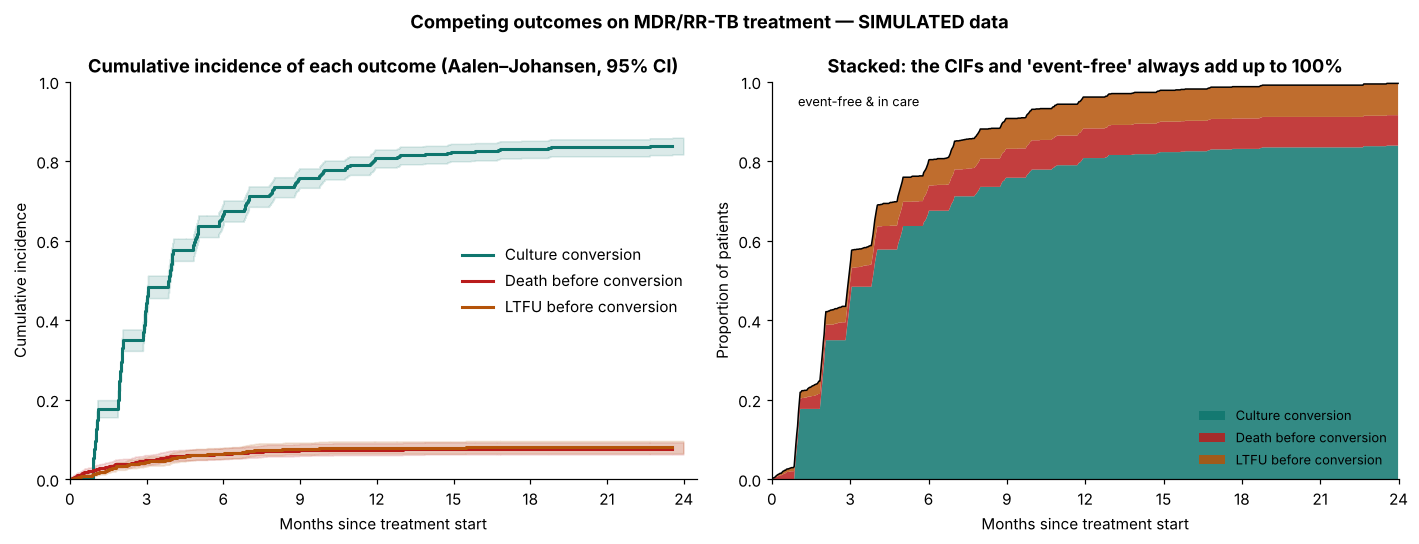

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cols = {1: TEAL, 2: RED, 3: AMBER}
for k, name in CAUSES.items():
    exact, lo, hi, _ = cif_curves[k]
    axes[0].step(exact.index / MONTH, exact.values, where="post", color=cols[k], lw=2, label=name)
    axes[0].fill_between(lo.index / MONTH, lo.values, hi.values, step="post", color=cols[k], alpha=.15)
axes[0].set(xlim=(0, 24.5), ylim=(0, 1), xlabel="Months since treatment start", ylabel="Cumulative incidence",
            title="Cumulative incidence of each outcome (Aalen–Johansen, 95% CI)")
axes[0].set_xticks(range(0, 25, 3)); axes[0].legend(frameon=False, loc="center right")

grid = np.arange(0, 731)
stack = np.vstack([[step_at(cif_curves[k][0], t) for t in grid] for k in (1, 2, 3)])
axes[1].stackplot(grid / MONTH, stack, colors=[TEAL, RED, AMBER], alpha=.85, labels=list(CAUSES.values()))
axes[1].plot(grid / MONTH, stack.sum(0), color="black", lw=1)
axes[1].text(1.0, .97, "event-free & in care", fontsize=8.5, va="top")
axes[1].set(xlim=(0, 24), ylim=(0, 1), xlabel="Months since treatment start", ylabel="Proportion of patients",
            title="Stacked: the CIFs and 'event-free' always add up to 100%")
axes[1].set_xticks(range(0, 25, 3)); axes[1].legend(frameon=False, loc="lower right", fontsize=8.5)
fig.suptitle("Competing outcomes on MDR/RR-TB treatment — SIMULATED data", fontweight="bold")
fig.tight_layout(); fig.savefig(OUT / "04_cumulative_incidence.png", dpi=150); plt.show()

### 9.2 Why 1 − Kaplan–Meier is the wrong answer

Now the naive analysis: treat death and LTFU as ordinary censoring and plot 1 − KM for each event. The gap between the dashed (naive) and solid (Aalen–Johansen) lines is the bias.

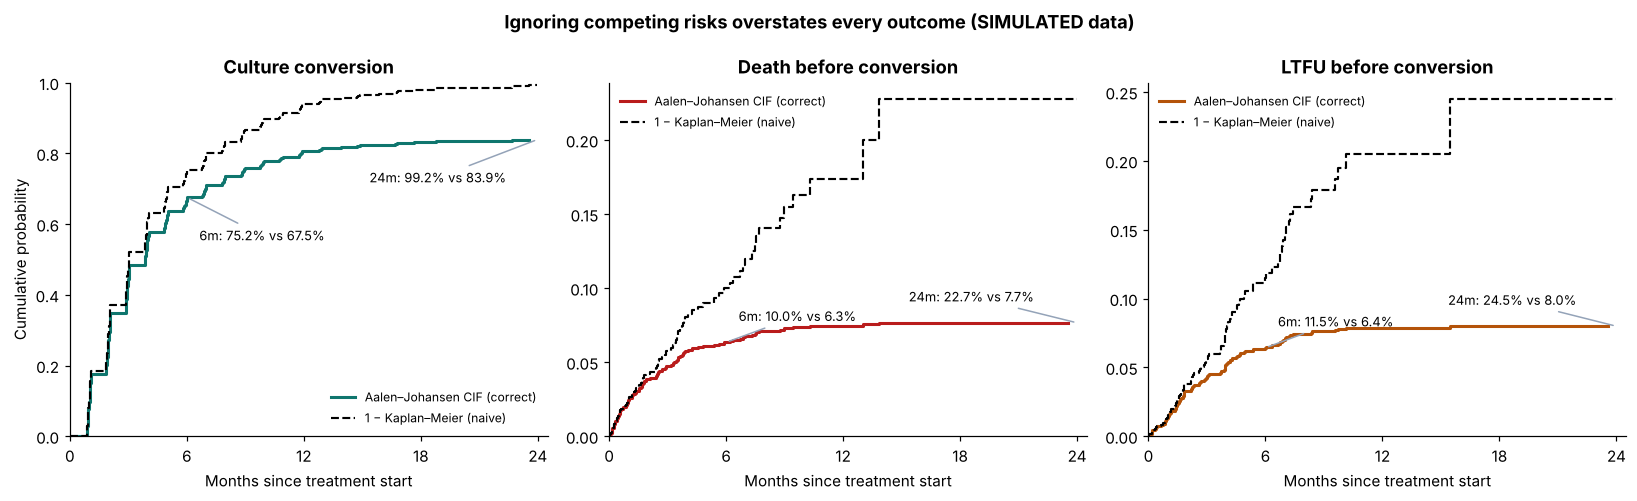

Median time to culture conversion: 118 days (3.9 months) from the CIF | 93 days from naive 1-KM


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (k, name) in zip(axes, CAUSES.items()):
    exact, _, _, naive = cif_curves[k]
    ax.step(exact.index / MONTH, exact.values, where="post", color=cols[k], lw=2, label="Aalen–Johansen CIF (correct)")
    ax.step(naive.index / MONTH, naive.values, where="post", color="black", ls="--", lw=1.4, label="1 − Kaplan–Meier (naive)")
    for lab, t in [("6m", 183), ("24m", 730)]:
        a, b = step_at(exact, t), step_at(naive, t)
        ax.annotate(f"{lab}: {b:.1%} vs {a:.1%}", (t / MONTH, a), xytext=(-110 if t > 400 else 8, -28 if k == 1 else 14),
                    textcoords="offset points", fontsize=8.5, arrowprops=dict(arrowstyle="-", color=GREY))
    ax.set(title=name, xlabel="Months since treatment start", xlim=(0, 24.5), ylim=(0, 1 if k == 1 else None))
    ax.set_xticks(range(0, 25, 6)); ax.legend(frameon=False, fontsize=8, loc="lower right" if k == 1 else "upper left")
axes[0].set_ylabel("Cumulative probability")
fig.suptitle("Ignoring competing risks overstates every outcome (SIMULATED data)", fontweight="bold")
fig.tight_layout(); fig.savefig(OUT / "05_naive_km_vs_aalen_johansen.png", dpi=150); plt.show()

# Median time to conversion: where each curve first reaches 50%
cif_conv, naive_conv = cif_curves[1][0], cif_curves[1][3]
med_cif = cif_conv.index[np.argmax(cif_conv.values >= .5)]
med_naive = naive_conv.index[np.argmax(naive_conv.values >= .5)]
print(f"Median time to culture conversion: {med_cif:.0f} days ({med_cif/MONTH:.1f} months) from the CIF | "
      f"{med_naive:.0f} days from naive 1-KM")

**Interpretation:** this is the central methodological result:

| | 6 months: 1 − KM vs CIF | 24 months: 1 − KM vs CIF |
|---|---|---|
| Conversion | 75.2% vs **67.5%** (+7.7 points) | 99.2% vs **83.9%** (+15.3 points) |
| Death before conversion | 10.0% vs **6.3%** | 22.7% vs **7.7%** (about 3×) |
| LTFU before conversion | 11.5% vs **6.4%** | 24.5% vs **8.0%** (about 3×) |

* The naive analysis claims that **99% of patients convert by 24 months**. In reality 16% of patients never convert during follow-up, almost all because they died or were lost first. A programme reporting 99% would badly overstate treatment success.
* The bias grows with time, because the longer the follow-up, the more patients have been removed by competing events and "resurrected" by the KM assumption.
* The **median time to conversion** shifts too: half of all patients have converted by **118 days (3.9 months)** according to the CIF, versus 93 days from naive 1 − KM.
* The naive death and LTFU curves are distorted most. Because conversion removes most patients early, treating it as censoring leaves a small, high-risk group "at risk", and their deaths are scaled up as if they represented everyone.

**Bottom line:** whenever another event can *prevent* the event of interest, report CIFs (Aalen–Johansen), not 1 − KM.

### 9.3 Cumulative incidence by group

CIFs can be compared between groups to show **absolute** differences, which are what clinicians and programme managers plan with. (Gray's test, the formal k-sample test for CIFs, is not available in lifelines or base `survival`; formal comparisons come from the cause-specific Cox models in Section 10.)

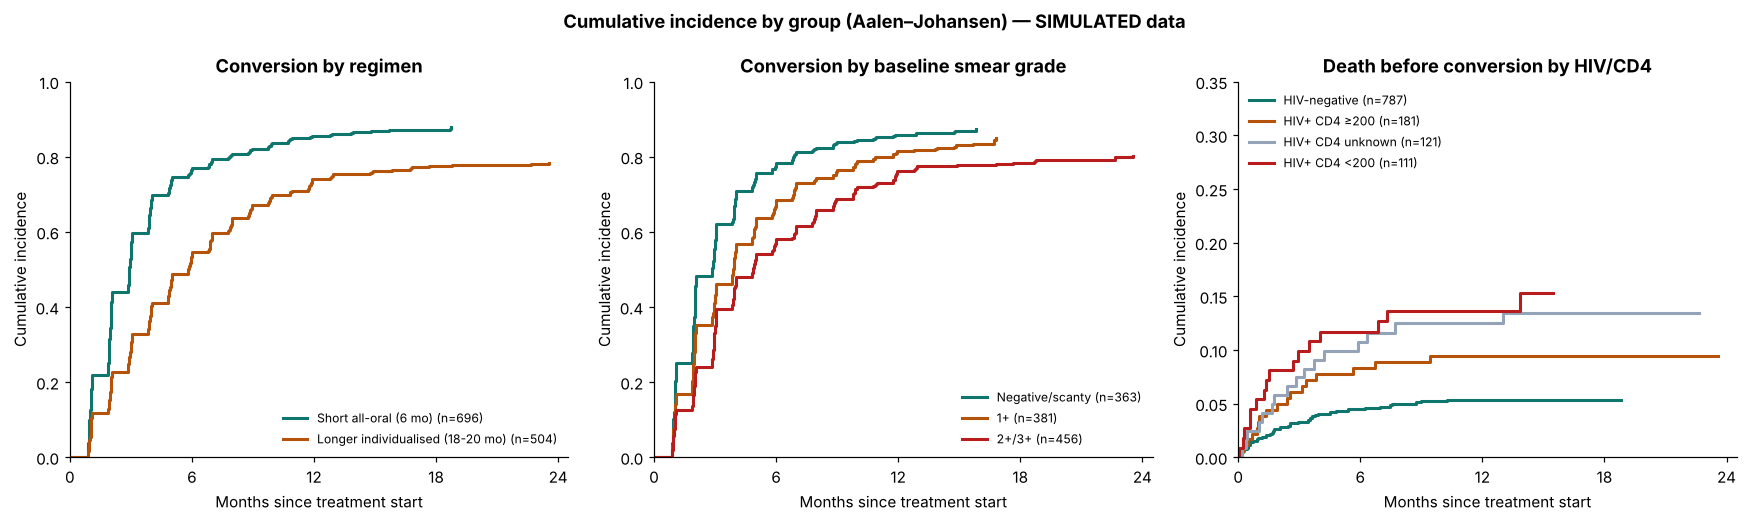

,comparison,group,n,CIF 2m,CIF 6m,CIF 12m,CIF 24m
0,Conversion by regimen,Short all-oral (6 mo),696,0.373,0.769,0.856,0.878
1,Conversion by regimen,Longer individualised (18-20 mo),504,0.187,0.546,0.741,0.784
2,Conversion by baseline smear grade,Negative/scanty,363,0.397,0.784,0.859,0.873
3,Conversion by baseline smear grade,1+,381,0.305,0.684,0.814,0.849
4,Conversion by baseline smear grade,2+/3+,456,0.204,0.581,0.761,0.802
5,Death before conversion by HIV/CD4,HIV-negative,787,0.027,0.045,0.054,0.054
6,Death before conversion by HIV/CD4,HIV+ CD4 ≥200,181,0.050,0.083,0.095,0.095
7,Death before conversion by HIV/CD4,HIV+ CD4 unknown,121,0.058,0.107,0.125,0.135
8,Death before conversion by HIV/CD4,HIV+ CD4 <200,111,0.081,0.117,0.136,0.153


In [16]:
def cif_by(ax, var, order, palette, cause, title, ylim):
    out = []
    for lev, col in zip(order, palette):
        m = d[var] == lev
        c = aalen_johansen(d.time[m], d.status[m], cause)
        ax.step(c.index / MONTH, c.values, where="post", color=col, lw=2, label=f"{lev} (n={m.sum()})")
        out.append([title, lev, m.sum()] + [step_at(c, t) for t in (61, 183, 365, 730)])
    ax.set(title=title, xlabel="Months since treatment start", ylabel="Cumulative incidence", xlim=(0, 24.5), ylim=ylim)
    ax.set_xticks(range(0, 25, 6)); ax.legend(frameon=False, fontsize=8, loc="lower right" if cause == 1 else "upper left")
    return out

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
rows = cif_by(axes[0], "regimen", ["Short all-oral (6 mo)", "Longer individualised (18-20 mo)"], [TEAL, AMBER], 1,
              "Conversion by regimen", (0, 1))
rows += cif_by(axes[1], "baseline_smear_grade", ["Negative/scanty", "1+", "2+/3+"], [TEAL, AMBER, RED], 1,
               "Conversion by baseline smear grade", (0, 1))
rows += cif_by(axes[2], "hiv_cd4", ["HIV-negative", "HIV+ CD4 ≥200", "HIV+ CD4 unknown", "HIV+ CD4 <200"],
               [TEAL, AMBER, GREY, RED], 2, "Death before conversion by HIV/CD4", (0, .35))
fig.suptitle("Cumulative incidence by group (Aalen–Johansen) — SIMULATED data", fontweight="bold")
fig.tight_layout(); fig.savefig(OUT / "06_cif_by_group.png", dpi=150); plt.show()
cif_grp = pd.DataFrame(rows, columns=["comparison", "group", "n", "CIF 2m", "CIF 6m", "CIF 12m", "CIF 24m"])
cif_grp.to_csv(OUT / "cif_by_group.csv", index=False)
cif_grp.round(3)

**Interpretation:**

* **Regimen:** **76.9%** of patients on the short all-oral regimen have converted by 6 months, versus **54.6%** on longer individualised regimens. By 24 months the gap narrows (87.8% vs 78.4%), a first hint that the regimen effect is concentrated early (Section 11).
* **Smear grade** shows a clear dose-response: 78.4%, 68.4% and 58.1% converted by 6 months for negative/scanty, 1+ and 2+/3+ respectively. A higher bacillary load takes longer to clear.
* **Death before conversion** rises steeply with immunosuppression: by 24 months 5.4% of HIV-negative patients, 9.5% with CD4 ≥ 200, 13.5% with unknown CD4 and **15.3% with CD4 < 200** have died before converting.
* These are **unadjusted** absolute risks. Regimen allocation, for example, depends on resistance pattern and treatment history, which the Cox models adjust for.

## 10. Cause-specific Cox proportional hazards models

### 10.1 What the model does

For each cause $k$, the cause-specific hazard is modelled as

$$h_k(t \mid x) = h_{k0}(t)\,\exp(\beta_k^\top x)$$

* $h_{k0}(t)$ is an unspecified baseline hazard: the Cox model makes **no assumption about its shape**.
* $\exp(\beta)$ is a **cause-specific hazard ratio (HR)**: how many times faster the event happens, at any moment, among patients still event-free, per unit of the covariate, holding the others fixed.
* For conversion, **HR > 1 is good** (faster conversion); for death and LTFU, **HR > 1 is bad**.
* Competing events are **censored at the time they happen**. For the conversion model a death on day 40 is "censored at day 40": the patient was at risk of converting until day 40 and not after.
* Tied event times are handled with **Efron's method** (lifelines' only method and R's default), so Python and R estimates should agree to numerical precision.

### 10.2 Covariates and pre-specified model sets

All models adjust for clinically motivated covariates chosen *before* looking at associations (no stepwise selection, which inflates false positives and gives biased, over-confident estimates). Continuous variables are kept continuous and scaled so their HRs are readable: **age per 10 years**, **adherence per 10 percentage points below 90%**, **distance per 10 km**.

| Model | Events | Covariates | Why this set |
|---|---|---|---|
| Conversion | 942 | age, sex, HIV/CD4, undernutrition, diabetes, smoking, previous TB treatment, cavitation, smear grade, pre-XDR, regimen, adherence, distance | Full set: plenty of events |
| Death before conversion | 88 | age, sex, HIV/CD4, not on ART, undernutrition, diabetes, cavitation, high smear grade (2+/3+), pre-XDR, regimen | Smaller, clinically chosen set: 7.3 events per parameter, below the traditional 10 but within the 5–9 range where simulation studies found acceptable Cox-model performance (Vittinghoff & McCulloch 2007) |
| LTFU before conversion | 92 | age < 25, sex, HIV, smoking, previous TB treatment, regimen, adherence, distance | Drivers of disengagement from care |

In [17]:
LABELS = {
    "age10": "Age (per 10 years)", "male": "Male sex", "age_under25": "Age < 25 years",
    "hiv_cd4_200plus": "HIV+ CD4 ≥200 (vs HIV−)", "hiv_cd4_lt200": "HIV+ CD4 <200 (vs HIV−)",
    "hiv_cd4_unknown": "HIV+ CD4 unknown (vs HIV−)", "hiv_pos": "HIV-positive", "no_art": "HIV+ not on ART",
    "undernutrition": "Undernutrition (BMI < 18.5)", "diabetes": "Diabetes", "smoker": "Current smoker",
    "prev_tb": "Previous TB treatment", "cavitary": "Cavitary disease", "smear_1plus": "Smear 1+ (vs neg/scanty)",
    "smear_2plus": "Smear 2+/3+ (vs neg/scanty)", "smear_high": "Smear 2+/3+ (vs lower)", "pre_xdr": "Pre-XDR (vs RR/MDR)",
    "short_regimen": "Short all-oral regimen", "adherence_def10": "Adherence (per 10% below 90%)",
    "distance10": "Distance to clinic (per 10 km)",
    "short_0_135": "Short regimen, days 0–135", "short_after135": "Short regimen, after day 135"}

def design(df):
    X = pd.DataFrame(index=df.index)
    X["age10"], X["male"] = df.age10, df.male
    X["age_under25"] = (df.age_years < 25).astype(int)
    X["hiv_cd4_200plus"] = (df.hiv_cd4 == "HIV+ CD4 ≥200").astype(int)
    X["hiv_cd4_lt200"] = (df.hiv_cd4 == "HIV+ CD4 <200").astype(int)
    X["hiv_cd4_unknown"] = (df.hiv_cd4 == "HIV+ CD4 unknown").astype(int)
    X["hiv_pos"], X["no_art"] = df.hiv_pos, df.no_art
    X["undernutrition"] = df.undernutrition.astype(int)
    X["diabetes"], X["smoker"], X["prev_tb"], X["cavitary"] = df.diabetes_y, df.smoker, df.prev_tb, df.cavitary
    X["smear_1plus"] = (df.baseline_smear_grade == "1+").astype(int)
    X["smear_2plus"] = (df.baseline_smear_grade == "2+/3+").astype(int)
    X["smear_high"] = X.smear_2plus
    X["pre_xdr"], X["short_regimen"] = df.pre_xdr, df.short_regimen
    X["adherence_def10"], X["distance10"] = df.adherence_def10, df.distance10
    return X

HIV3 = ["hiv_cd4_200plus", "hiv_cd4_lt200", "hiv_cd4_unknown"]
TERMS = {
    1: ["age10", "male", *HIV3, "undernutrition", "diabetes", "smoker", "prev_tb", "cavitary", "smear_1plus", "smear_2plus",
        "pre_xdr", "short_regimen", "adherence_def10", "distance10"],
    2: ["age10", "male", *HIV3, "no_art", "undernutrition", "diabetes", "cavitary", "smear_high", "pre_xdr", "short_regimen"],
    3: ["age_under25", "male", "hiv_pos", "smoker", "prev_tb", "short_regimen", "adherence_def10", "distance10"]}
# variables entered together in univariable models (multi-level factors stay together)
UNI_GROUPS = {1: [["age10"], ["male"], HIV3, ["undernutrition"], ["diabetes"], ["smoker"], ["prev_tb"], ["cavitary"],
                  ["smear_1plus", "smear_2plus"], ["pre_xdr"], ["short_regimen"], ["adherence_def10"], ["distance10"]],
              2: [["age10"], ["male"], HIV3, ["no_art"], ["undernutrition"], ["diabetes"], ["cavitary"], ["smear_high"],
                  ["pre_xdr"], ["short_regimen"]]}

X_all = design(model_df)
def cs_data(cause, terms, df=model_df, X=None):
    X = X_all if X is None else X
    return pd.concat([df[["time"]], (df.status == cause).astype(int).rename("event"), X.loc[df.index, terms]], axis=1)

def tidy(cph, model):
    s = cph.summary
    return pd.DataFrame({"model": model, "term": s.index, "label": [LABELS[t] for t in s.index], "HR": s["exp(coef)"],
                         "lower": s["exp(coef) lower 95%"], "upper": s["exp(coef) upper 95%"], "p": s["p"],
                         "coef": s["coef"], "se": s["se(coef)"]}).reset_index(drop=True)

fits, results = {}, {}
for k, name in CAUSES.items():
    data = cs_data(k, TERMS[k])
    fits[k] = CoxPH().fit(data, "time", "event")
    results[k] = tidy(fits[k], f"{name} (multivariable)")
    print(f"{name}: n = {len(data)}, events = {data.event.sum()}, parameters = {len(TERMS[k])}, "
          f"events per parameter = {data.event.sum() / len(TERMS[k]):.1f}")
uni = {}
for k in (1, 2):
    uni[k] = pd.concat([tidy(CoxPH().fit(cs_data(k, g), "time", "event"), f"{CAUSES[k]} (univariable)") for g in UNI_GROUPS[k]])

Culture conversion: n = 1148, events = 942, parameters = 16, events per parameter = 58.9
Death before conversion: n = 1148, events = 88, parameters = 12, events per parameter = 7.3
LTFU before conversion: n = 1148, events = 92, parameters = 8, events per parameter = 11.5


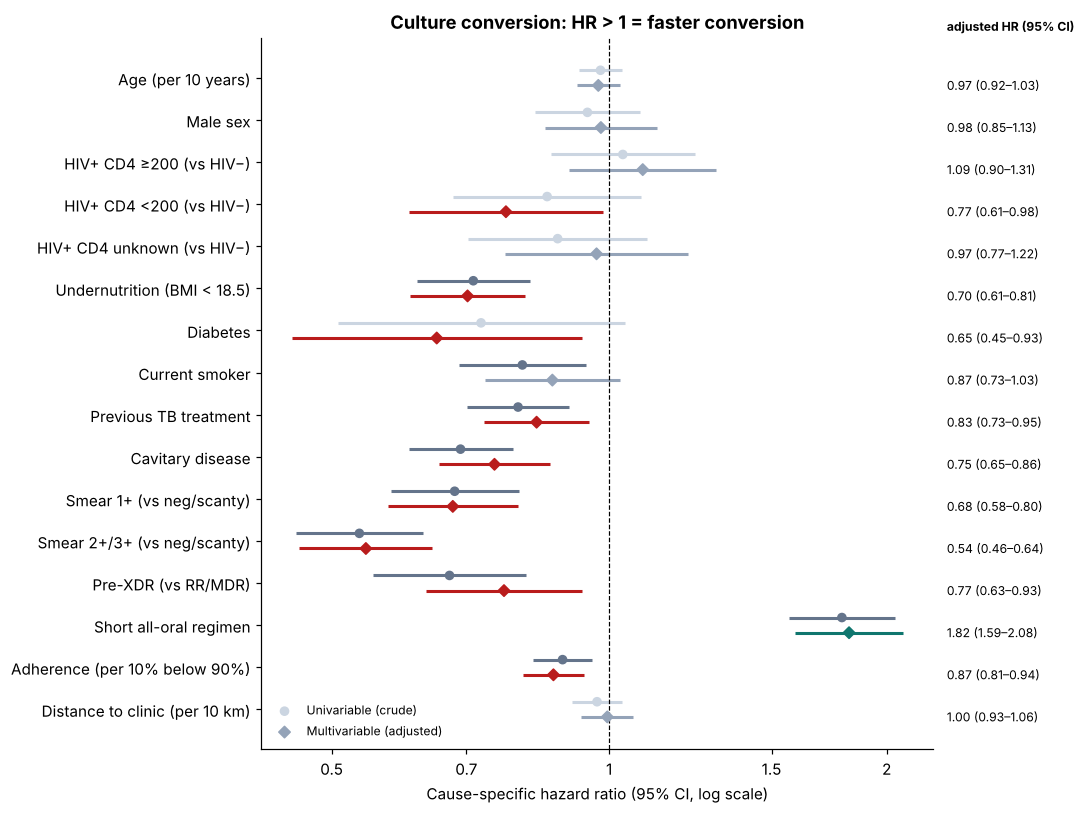

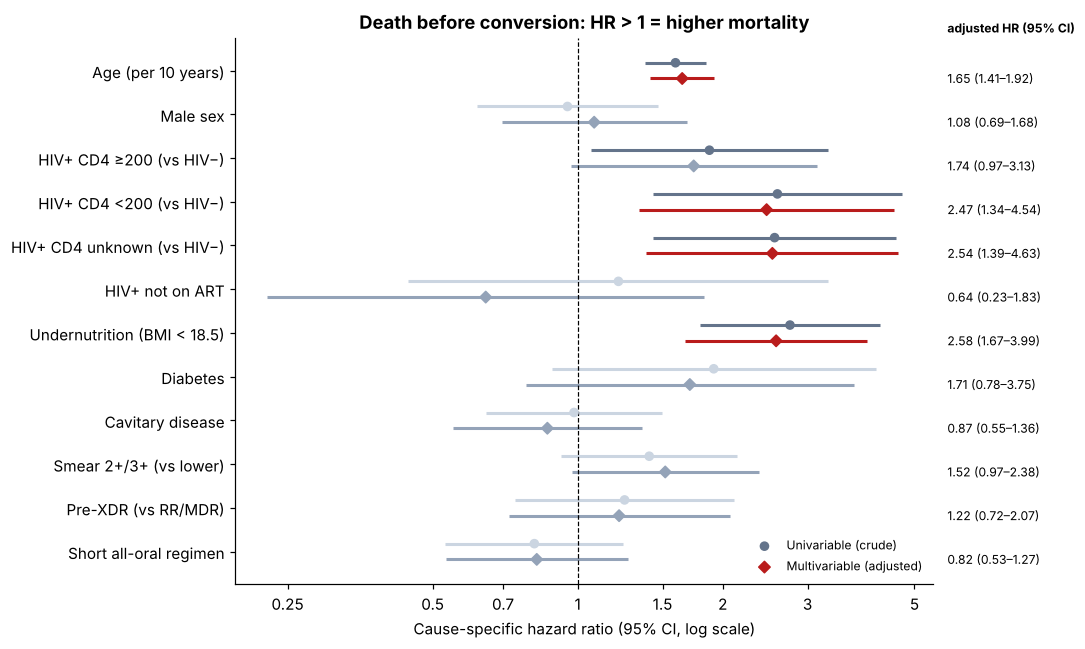

CONVERSION (multivariable)


,label,HR (95% CI),p
0,Age (per 10 years),0.97 (0.92–1.03),0.328
1,Male sex,0.98 (0.85–1.13),0.773
2,HIV+ CD4 ≥200 (vs HIV−),1.09 (0.90–1.31),0.372
3,HIV+ CD4 <200 (vs HIV−),0.77 (0.61–0.98),0.036
4,HIV+ CD4 unknown (vs HIV−),0.97 (0.77–1.22),0.786
5,Undernutrition (BMI < 18.5),0.70 (0.61–0.81),<0.001
6,Diabetes,0.65 (0.45–0.93),0.020
7,Current smoker,0.87 (0.73–1.03),0.098
8,Previous TB treatment,0.83 (0.73–0.95),0.006
9,Cavitary disease,0.75 (0.65–0.86),<0.001


In [18]:
def forest(ax, multi, uni_df, title, good_high):
    m = multi.set_index("term"); u = uni_df.set_index("term").reindex(m.index)
    y = np.arange(len(m))[::-1]
    for (tab, off, mk, lab) in [(u, .18, "o", "Univariable (crude)"), (m, -.18, "D", "Multivariable (adjusted)")]:
        sig = tab.p < .05
        good = (tab.HR > 1) == good_high
        col = np.where(~sig, GREY, np.where(good, TEAL, RED))
        if mk == "o":
            col = np.where(sig, "#64748b", "#cbd5e1")
        ax.hlines(y + off, tab.lower, tab.upper, color=col, lw=2)
        ax.scatter(tab.HR, y + off, c=col, marker=mk, s=28, zorder=3, label=lab)
    ax.axvline(1, color="black", lw=.8, ls="--"); ax.set_xscale("log"); log_ticks(ax)
    ax.set_yticks(y); ax.set_yticklabels(m.label)
    for yi, (hr, lo, hi) in zip(y, m[["HR", "lower", "upper"]].values):
        ax.text(1.02, yi - .18, f"{hr:.2f} ({lo:.2f}–{hi:.2f})", transform=ax.get_yaxis_transform(), fontsize=8, va="center")
    ax.set(title=title, xlabel="Cause-specific hazard ratio (95% CI, log scale)")
    ax.legend(frameon=False, fontsize=8, loc="lower left" if good_high else "lower right")

fig, ax = plt.subplots(figsize=(10, 7.5))
forest(ax, results[1], uni[1], "Culture conversion: HR > 1 = faster conversion", good_high=True)
ax.text(1.02, 1.01, "adjusted HR (95% CI)", transform=ax.transAxes, fontsize=8, weight="bold")
fig.tight_layout(); fig.savefig(OUT / "07_forest_conversion.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
forest(ax, results[2], uni[2], "Death before conversion: HR > 1 = higher mortality", good_high=False)
ax.text(1.02, 1.01, "adjusted HR (95% CI)", transform=ax.transAxes, fontsize=8, weight="bold")
fig.tight_layout(); fig.savefig(OUT / "08_forest_death.png", dpi=150); plt.show()

hr_table = pd.concat([results[1], uni[1], results[2], uni[2], results[3]])
hr_table.to_csv(OUT / "cox_cause_specific_hazard_ratios.csv", index=False)
show = lambda r: r.assign(**{"HR (95% CI)": r.apply(lambda x: f"{x.HR:.2f} ({x.lower:.2f}–{x.upper:.2f})", axis=1),
                             "p": r.p.map(lambda p: "<0.001" if p < .001 else f"{p:.3f}")})[["label", "HR (95% CI)", "p"]]
print("CONVERSION (multivariable)"); display(show(results[1]))

**Interpretation — conversion** (942 conversions; adjusted HR < 1 = slower conversion):

* **Bacillary burden and lung damage slow conversion the most:** smear 2+/3+ HR **0.54** (0.46–0.64) and 1+ HR 0.68 (0.58–0.80) vs negative/scanty; **cavitary disease 0.75** (0.65–0.86). At any time, a not-yet-converted patient with a 2+/3+ smear converts at roughly half the rate of a smear-negative patient.
* **Host factors:** **undernutrition 0.70** (0.61–0.81), **diabetes 0.65** (0.45–0.93), HIV with **CD4 < 200 0.77** (0.61–0.98), previous TB treatment 0.83 (0.73–0.95).
* **Resistance:** pre-XDR 0.77 (0.63–0.93).
* **Adherence:** each 10 percentage points below 90% DOT adherence gives HR **0.87** (0.81–0.94). This is the one *modifiable* factor in the model.
* **Short all-oral regimen: HR 1.82** (1.59–2.08). This average hides a time-varying effect (Section 11).
* **Not associated:** age, sex, distance to clinic, HIV with CD4 ≥ 200. Smoking was significant crude (0.81, p = 0.007) but not after adjustment (0.87, 0.73–1.03). Smokers are mostly men and have lower adherence, which explains much of the crude association.
* **Crude vs adjusted:** two shifts are worth explaining. **HIV with CD4 < 200** is non-significant crude (0.86) but significant adjusted (0.77). Low-CD4 patients have fewer cavities (Table 1), which on its own speeds conversion, so the crude comparison hides their slower response until cavitation is adjusted for (negative confounding). **Pre-XDR** moves from 0.67 crude to 0.77 adjusted, because part of its crude effect works through being given a longer regimen.

DEATH BEFORE CONVERSION (multivariable)


,label,HR (95% CI),p
0,Age (per 10 years),1.65 (1.41–1.92),<0.001
1,Male sex,1.08 (0.69–1.68),0.728
2,HIV+ CD4 ≥200 (vs HIV−),1.74 (0.97–3.13),0.065
3,HIV+ CD4 <200 (vs HIV−),2.47 (1.34–4.54),0.004
4,HIV+ CD4 unknown (vs HIV−),2.54 (1.39–4.63),0.002
5,HIV+ not on ART,0.64 (0.23–1.83),0.410
6,Undernutrition (BMI < 18.5),2.58 (1.67–3.99),<0.001
7,Diabetes,1.71 (0.78–3.75),0.181
8,Cavitary disease,0.87 (0.55–1.36),0.528
9,Smear 2+/3+ (vs lower),1.52 (0.97–2.38),0.067


LTFU BEFORE CONVERSION (multivariable)


,label,HR (95% CI),p
0,Age < 25 years,1.58 (0.92–2.73),0.098
1,Male sex,1.61 (0.93–2.77),0.086
2,HIV-positive,0.96 (0.60–1.51),0.845
3,Current smoker,1.85 (1.18–2.92),0.008
4,Previous TB treatment,0.75 (0.50–1.15),0.187
5,Short all-oral regimen,0.74 (0.48–1.14),0.170
6,Adherence (per 10% below 90%),1.40 (1.15–1.70),<0.001
7,Distance to clinic (per 10 km),1.11 (0.96–1.28),0.154


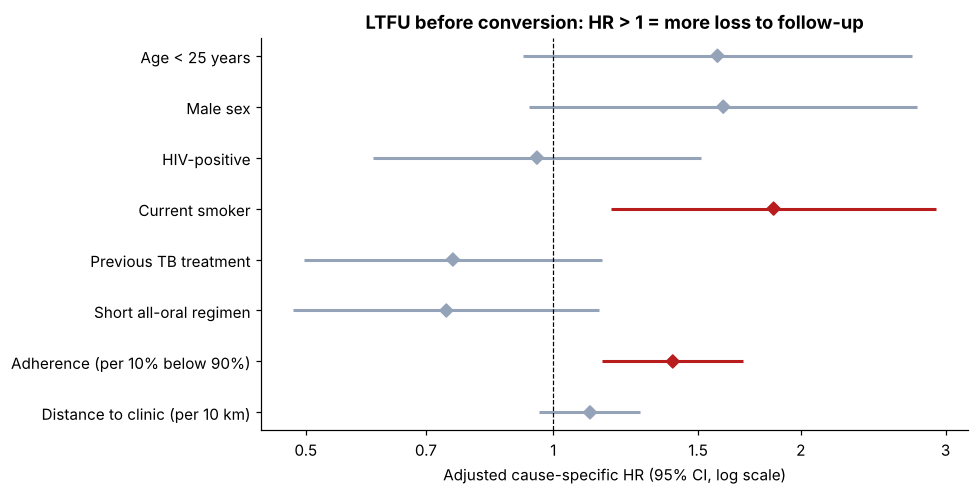

In [19]:
print("DEATH BEFORE CONVERSION (multivariable)"); display(show(results[2]))
print("LTFU BEFORE CONVERSION (multivariable)"); display(show(results[3]))
fig, ax = plt.subplots(figsize=(9, 4.6))
r3 = results[3].iloc[::-1]
col = np.where(r3.p >= .05, GREY, np.where(r3.HR > 1, RED, TEAL))
ax.hlines(range(len(r3)), r3.lower, r3.upper, color=col, lw=2); ax.scatter(r3.HR, range(len(r3)), color=col, marker="D", zorder=3)
ax.axvline(1, color="black", ls="--", lw=.8); ax.set_xscale("log"); log_ticks(ax); ax.set_yticks(range(len(r3))); ax.set_yticklabels(r3.label)
ax.set(title="LTFU before conversion: HR > 1 = more loss to follow-up", xlabel="Adjusted cause-specific HR (95% CI, log scale)")
fig.tight_layout(); fig.savefig(OUT / "09_forest_ltfu.png", dpi=150); plt.show()

**Interpretation — death before conversion** (88 deaths, 12 parameters, 7.3 events per parameter):

* **Age:** HR **1.65 per 10 years** (1.41–1.92).
* **HIV:** CD4 < 200 HR **2.47** (1.34–4.54) and CD4 unknown HR **2.54** (1.39–4.63) vs HIV-negative. CD4 ≥ 200 is borderline (1.74, 0.97–3.13).
* **Undernutrition: HR 2.58** (1.67–3.99), a risk as large as advanced HIV, and it affects a third of the cohort.
* High smear grade 1.52 (0.97–2.38) and diabetes 1.71 (0.78–3.75) point towards higher risk but are imprecise. Only 43 patients in the regression set have diabetes, and 7 of them died before converting.
* **"HIV+ not on ART" HR 0.64 (0.23–1.83)** runs against clinical expectation. Only 46 patients are not on ART, so the interval spans everything from strong protection to nearly doubled risk. **The estimate is uninformative and should not be interpreted.** Section 13 shows the true simulated effect was harmful (HR 1.7), a good illustration of why tiny subgroups shouldn't be over-read.
* Regimen (0.82, 0.53–1.27) and pre-XDR (1.22, 0.72–2.07) are not significantly associated with death *before conversion*.

**LTFU before conversion** (92 events):

* **Low adherence** is the strongest driver: HR **1.40 per 10 points below 90%** (1.15–1.70). Missing doses early in treatment flags disengagement.
* **Current smoking** HR 1.85 (1.18–2.92). Male sex (1.61, 0.93–2.77) and age < 25 (1.58, 0.92–2.73) point the same way but are not significant.
* Distance to clinic: HR 1.11 per 10 km (0.96–1.28), a weak and non-significant association in this sample.
* The apparent protective effect of the short regimen (0.74) is **not** a lower LTFU rate. It is an artefact of time at risk, explained in Section 11.

## 11. Checking the proportional-hazards assumption

### 11.1 What PH means and how it is tested

A Cox model summarises each covariate with **one** HR that applies at every point in follow-up. If the effect actually changes over time (strong early, gone later), the single HR is an average that can mislead.

**Schoenfeld residuals** test this. At each event time, the residual for a covariate is the difference between the covariate value of the patient who had the event and its risk-weighted average among everyone at risk. If PH holds, the *scaled* residuals have no trend over time. We test for a correlation between the scaled residuals and (Kaplan–Meier-transformed) time: a small p-value indicates a time-varying effect. lifelines' `proportional_hazard_test` and R's `cox.zph` implement closely related versions of this test (R ≥ 3.0 uses a score test, so p-values differ slightly while conclusions agree).

Because we run many tests (one per covariate per model), we use a stricter threshold of **p < 0.01** and look at the residual plots, rather than treating every p < 0.05 as a violation.

In [20]:
ph_rows = []
for k, name in CAUSES.items():
    res = proportional_hazard_test(fits[k], cs_data(k, TERMS[k]), time_transform="km").summary
    ph_rows.append(res.assign(model=name, label=[LABELS[t] for t in res.index]).reset_index(names="term"))
ph = pd.concat(ph_rows)[["model", "term", "label", "test_statistic", "p"]]
ph.to_csv(OUT / "ph_tests_schoenfeld.csv", index=False)
print("Covariates with p < 0.05 in the Schoenfeld test:")
display(ph[ph.p < .05].round(4))
print(f"\nAll other covariates: p ≥ 0.05 ({(ph.p >= .05).sum()} of {len(ph)} tests)")

Covariates with p < 0.05 in the Schoenfeld test:


,model,term,label,test_statistic,p
11,Culture conversion,short_regimen,Short all-oral regimen,11.6255,0.0007
2,Death before conversion,diabetes,Diabetes,4.3858,0.0362
6,Death before conversion,male,Male sex,3.8435,0.0499
6,LTFU before conversion,short_regimen,Short all-oral regimen,5.5719,0.0183



All other covariates: p ≥ 0.05 (32 of 36 tests)


In [21]:
# Follow-up 1: diabetes in the death model - how much information is there?
dd2 = cs_data(2, TERMS[2])
print(f"Diabetes: {dd2.diabetes.sum()} patients, {dd2.event[dd2.diabetes == 1].sum()} deaths before conversion")
strat = CoxPH().fit(dd2, "time", "event", strata=["diabetes"])
cmp_ = pd.DataFrame({"HR main model": fits[2].hazard_ratios_.drop("diabetes"), "HR stratified on diabetes": strat.hazard_ratios_})
cmp_["% change"] = 100 * (cmp_.iloc[:, 1] / cmp_.iloc[:, 0] - 1)
print(f"Death model stratified on diabetes: largest change in any other HR = {cmp_['% change'].abs().max():.1f}%")

# Follow-up 2: regimen and LTFU - compare like with like (both groups are on treatment only during months 0-6)
ltfu6 = cs_data(3, TERMS[3]).assign(event=lambda x: np.where(x.time <= 183, x.event, 0), time=lambda x: np.minimum(x.time, 183))
f6 = CoxPH().fit(ltfu6, "time", "event")
r6 = f6.summary.loc["short_regimen"]
print(f"LTFU, first 6 months only ({ltfu6.event.sum()} of {cs_data(3, TERMS[3]).event.sum()} LTFU events): short vs longer regimen "
      f"HR = {r6['exp(coef)']:.2f} ({r6['exp(coef) lower 95%']:.2f}-{r6['exp(coef) upper 95%']:.2f}), p = {r6.p:.2f}")
p6 = proportional_hazard_test(f6, ltfu6, time_transform="km").summary
print(f"Schoenfeld test for regimen in the 6-month LTFU model: p = {p6.loc['short_regimen', 'p']:.2f}")
cmp_.round(3)

Diabetes: 43 patients, 7 deaths before conversion
Death model stratified on diabetes: largest change in any other HR = 7.3%
LTFU, first 6 months only (75 of 92 LTFU events): short vs longer regimen HR = 1.00 (0.63-1.60), p = 0.99
Schoenfeld test for regimen in the 6-month LTFU model: p = 0.87


,HR main model,HR stratified on diabetes,% change
covariate,,,
age10,1.648,1.668,1.243
male,1.082,1.041,-3.764
hiv_cd4_200plus,1.741,1.796,3.189
hiv_cd4_lt200,2.466,2.647,7.334
hiv_cd4_unknown,2.535,2.692,6.166
no_art,0.644,0.660,2.436
undernutrition,2.581,2.501,-3.113
cavitary,0.865,0.917,5.956
smear_high,1.519,1.446,-4.838


**Interpretation:**

* **Short regimen, conversion model: p = 0.0007.** This is the only result below the 0.01 threshold in lifelines, and R's `cox.zph` agrees (p < 0.001). The plots below show why.
* **Diabetes, death model** (lifelines p = 0.036; R `cox.zph` p = 0.009) and **male sex, death model** (p = 0.0499): borderline results, with about two expected by chance across 36 tests. The diabetes signal rests on **7 deaths**. Stratifying the death model on diabetes (which removes any PH assumption for it) changes every other HR by at most 7.3%, so the conclusions don't depend on it. In this simulation the true diabetes effect *is* constant, so the signal is a false positive. The two programs differ here because `cox.zph` (survival ≥ 3.0) uses a score test, while lifelines uses the older correlation-type test.
* **Short regimen, LTFU model** (lifelines p = 0.018; R p = 0.009): a **structural** violation. LTFU is defined only while on treatment, and short-regimen patients finish treatment at 6 months, so from month 6 onward they *cannot* be lost while longer-regimen patients still can. Comparing like with like, by restricting the LTFU model to the first 6 months when both groups are on treatment, gives **HR 1.00 (0.63–1.60)** with no remaining PH problem (p = 0.87). **The 0.74 "protective" effect comes entirely from less time at risk, not from better retention.** This is a good example of why a significant Schoenfeld test should prompt clinical thinking, not just a mechanical fix.

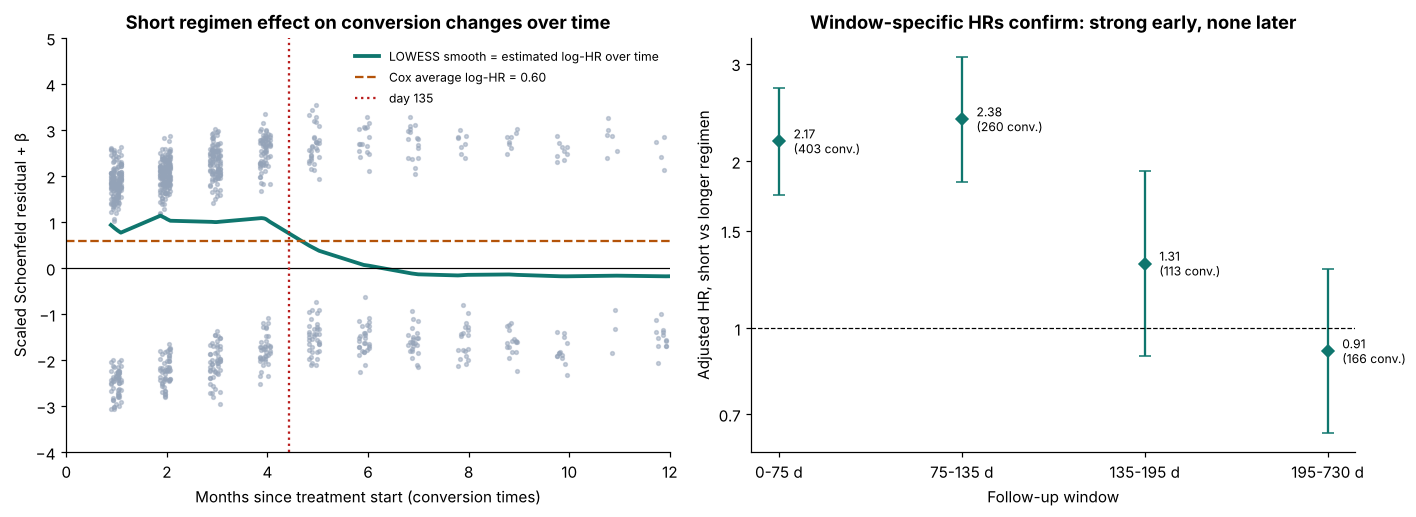

,window,HR,lower,upper,conversions
0,0-75 d,2.172,1.741,2.710,403
1,75-135 d,2.380,1.836,3.085,260
2,135-195 d,1.308,0.889,1.922,113
3,195-730 d,0.909,0.646,1.278,166


In [22]:
conv_data = cs_data(1, TERMS[1])
resid = fits[1].compute_residuals(conv_data, "scaled_schoenfeld")
ev_times = conv_data.loc[resid.index, "time"]
beta_t = resid["short_regimen"]        # scaled Schoenfeld residual ~ beta(t) - beta_hat
order = np.argsort(ev_times.values)
from statsmodels.nonparametric.smoothers_lowess import lowess
sm_ = lowess(beta_t.values + fits[1].params_["short_regimen"], ev_times.values, frac=.3, return_sorted=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(ev_times / MONTH, beta_t + fits[1].params_["short_regimen"], s=6, color=GREY, alpha=.5)
axes[0].plot(sm_[:, 0] / MONTH, sm_[:, 1], color=TEAL, lw=2.5, label="LOWESS smooth = estimated log-HR over time")
axes[0].axhline(fits[1].params_["short_regimen"], color=AMBER, ls="--", label=f"Cox average log-HR = {fits[1].params_['short_regimen']:.2f}")
axes[0].axhline(0, color="black", lw=.8); axes[0].axvline(135 / MONTH, color=RED, ls=":", label="day 135")
axes[0].set(xlim=(0, 12), ylim=(-4, 5), xlabel="Months since treatment start (conversion times)",
            ylabel="Scaled Schoenfeld residual + β", title="Short regimen effect on conversion changes over time")
axes[0].legend(frameon=False, fontsize=8)
# CIF by regimen on log time for intuition: hazard ratio over time windows
win = [(0, 75), (75, 135), (135, 195), (195, 730)]
hr_win = []
for a, b in win:
    sub = conv_data[conv_data.time > a].copy()
    sub["event"] = np.where(sub.time <= b, sub.event, 0); sub["time"] = np.minimum(sub.time, b)
    c = CoxPH().fit(sub.assign(entry=a), "time", "event", entry_col="entry")
    hr_win.append((f"{a}-{b} d", *c.summary.loc["short_regimen", ["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%"]],
                   int(sub.event.sum())))
hr_win = pd.DataFrame(hr_win, columns=["window", "HR", "lower", "upper", "conversions"])
axes[1].errorbar(range(len(hr_win)), hr_win.HR, yerr=[hr_win.HR - hr_win.lower, hr_win.upper - hr_win.HR], fmt="D",
                 color=TEAL, capsize=4)
axes[1].axhline(1, color="black", ls="--", lw=.8); axes[1].set_xticks(range(len(hr_win))); axes[1].set_xticklabels(hr_win.window)
for i, r in hr_win.iterrows():
    axes[1].text(i + .08, r.HR, f"{r.HR:.2f}\n({r.conversions} conv.)", fontsize=8, va="center")
axes[1].set(yscale="log", ylabel="Adjusted HR, short vs longer regimen", xlabel="Follow-up window",
            title="Window-specific HRs confirm: strong early, none later")
log_ticks(axes[1], "y", (0.5, 0.7, 1, 1.5, 2, 3))
fig.tight_layout(); fig.savefig(OUT / "10_ph_check_regimen.png", dpi=150); plt.show()
hr_win.round(3)

### 11.2 Remedy: let the regimen effect change at day 135 (episode splitting)

Options when PH fails for one covariate:

1. **Stratify** on it (separate baseline hazards). This fixes PH but gives *no HR* for that covariate, and regimen is a covariate we want to estimate.
2. **Time-varying coefficient** via a step function: split each patient's follow-up at a cut-point and estimate one HR per period. Simple, transparent and easy to explain clinically.
3. Interaction with a continuous function of time (e.g. β·log t) or flexible parametric (Royston–Parmar) models.

We use option 2 with a **cut at day 135**, midway between the month-4 (≈ day 120) and month-5 (≈ day 150) culture visits. That is where the residual plot shows the effect fading, and it is a clinically natural landmark: most conversions on an effective regimen are detected by the month-4 culture. Because conversion is only observed at visits, a cut *between* visits avoids splitting a visit's conversions across the two periods. *Honest caveat:* in a real study the cut-point should be pre-specified or chosen by a documented sensitivity analysis, because picking it after looking at the data makes the period-specific HRs slightly optimistic. Here the data were simulated with exactly this structure, so the choice can be checked against the truth (Section 13).

Each patient's follow-up is split into two rows, (0, min(t, 135)] and (135, t] if still at risk after day 135, and the model is fitted on these **counting-process** rows (`entry_col` in lifelines, `Surv(start, stop, event)` in R). Each patient contributes non-overlapping intervals, so the usual standard errors remain valid.

In [23]:
def split_at(df, cut=135):
    X = X_all.loc[df.index, TERMS[1]]
    base = pd.concat([df[["time"]], (df.status == 1).astype(int).rename("event"), X], axis=1)
    early = base.assign(start=0.0, stop=np.minimum(base.time, cut), event=np.where(base.time <= cut, base.event, 0))
    late = base[base.time > cut].assign(start=float(cut), stop=lambda x: x.time)
    out = pd.concat([early, late]).drop(columns="time")
    out["short_0_135"] = np.where(out.start == 0, out.short_regimen, 0)
    out["short_after135"] = np.where(out.start > 0, out.short_regimen, 0)
    return out.drop(columns="short_regimen")

ep = split_at(model_df)
print(f"{len(model_df):,} patients -> {len(ep):,} episode rows; conversions = {ep.event.sum()}")
fit_tv = CoxPH().fit(ep, "stop", "event", entry_col="start")
res_tv = tidy(fit_tv, "Culture conversion (time-split regimen)")
res_tv.to_csv(OUT / "cox_conversion_time_split.csv", index=False)
b, V = fit_tv.params_, fit_tv.variance_matrix_
diff = b["short_0_135"] - b["short_after135"]
se = np.sqrt(V.loc["short_0_135", "short_0_135"] + V.loc["short_after135", "short_after135"] - 2 * V.loc["short_0_135", "short_after135"])
p_diff = 2 * stats.norm.sf(abs(diff / se))
print(f"Wald test that the two regimen HRs are equal: z = {diff/se:.2f}, p = {p_diff:.2g}")
print(f"Partial log-likelihood: PH model {fits[1].log_likelihood_:.1f} vs time-split model {fit_tv.log_likelihood_:.1f} "
      f"(LR chi2 = {2*(fit_tv.log_likelihood_ - fits[1].log_likelihood_):.1f}, 1 df)")
display(show(res_tv))

1,148 patients -> 1,496 episode rows; conversions = 942
Wald test that the two regimen HRs are equal: z = 4.59, p = 4.4e-06
Partial log-likelihood: PH model -5600.2 vs time-split model -5589.3 (LR chi2 = 21.7, 1 df)


,label,HR (95% CI),p
0,Age (per 10 years),0.97 (0.92–1.02),0.281
1,Male sex,0.98 (0.85–1.13),0.805
2,HIV+ CD4 ≥200 (vs HIV−),1.07 (0.89–1.29),0.470
3,HIV+ CD4 <200 (vs HIV−),0.77 (0.61–0.98),0.035
4,HIV+ CD4 unknown (vs HIV−),0.97 (0.77–1.22),0.779
5,Undernutrition (BMI < 18.5),0.70 (0.60–0.80),<0.001
6,Diabetes,0.66 (0.46–0.95),0.024
7,Current smoker,0.87 (0.74–1.03),0.108
8,Previous TB treatment,0.84 (0.74–0.96),0.011
9,Cavitary disease,0.76 (0.66–0.87),<0.001


**Interpretation:** the time-split model fits much better (likelihood-ratio χ² = 21.7 on 1 df) and the two period-specific HRs differ clearly (Wald z = 4.59, p = 4.4 × 10⁻⁶):

* **Days 0–135: HR 2.27** (1.92–2.68). In the first four months the short all-oral regimen more than doubles the rate of culture conversion.
* **After day 135: HR 1.13** (0.89–1.45). Patients who are still culture-positive after about 4.5 months convert at a similar rate on either regimen.
* The other HRs barely change (for example, undernutrition 0.70, smear 2+/3+ 0.54, adherence 0.87). R's `cox.zph` on the split model finds no remaining violation (global p = 0.75; smallest covariate p = 0.15).

Clinically this is the expected pattern for a regimen with stronger early bactericidal activity: most of its benefit is **faster** sterilisation of sputum in the first months. Patients who have not converted by month 4–5 on the short regimen are a selected group, likely those with high bacillary load, cavitation or poor adherence, who need clinical review rather than an assumption that the regimen will catch up.

## 12. Model performance, overall-survival model and sensitivity analysis

### 12.1 Discrimination: Harrell's concordance index (C)

C is the proportion of comparable patient pairs in which the patient with the higher predicted risk has the event first: 0.5 = coin toss, 1 = perfect ranking, about 0.7 is typical for clinical prognostic models. Two caveats:

* The **apparent** C (computed on the data used to fit the model) is optimistic, so we also report **5-fold cross-validated** C.
* For cause-specific models, competing events are treated as censored, so C measures how well the model ranks the *cause-specific hazard*, not the absolute probability (CIF) of the event. Competing-risk-specific C-statistics (e.g. Wolbers' C) exist but are not implemented in lifelines.

### 12.2 Overall-survival Cox model (secondary outcome)

The all-cause mortality model uses the same covariates as the death-before-conversion model, but counts **all deaths during 24 months**, including those after conversion, and censors at LTFU, transfer and the cut-off.

In [24]:
os_data = pd.concat([model_df[["os_time", "died"]], X_all[TERMS[2]]], axis=1)
fit_os = CoxPH().fit(os_data, "os_time", "died")
res_os = tidy(fit_os, "Overall survival (all-cause death)")
res_os.to_csv(OUT / "cox_overall_survival.csv", index=False)
print(f"Overall-survival model: n = {len(os_data)}, deaths = {os_data.died.sum()}")
display(show(res_os))
ph_os = proportional_hazard_test(fit_os, os_data, time_transform="km").summary
print("Schoenfeld tests, OS model - smallest p-value:", f"{ph_os.p.min():.3f} ({LABELS[ph_os.p.idxmin()]})")

perf = []
for name, fitter, data, dur, ev, kw in [
        ("Culture conversion", fits[1], cs_data(1, TERMS[1]), "time", "event", {}),
        ("Death before conversion", fits[2], cs_data(2, TERMS[2]), "time", "event", {}),
        ("LTFU before conversion", fits[3], cs_data(3, TERMS[3]), "time", "event", {}),
        ("Overall survival (all-cause death)", fit_os, os_data, "os_time", "died", {})]:
    cv = k_fold_cross_validation(CoxPH(), data, dur, ev, k=5, scoring_method="concordance_index", seed=2024)
    perf.append([name, int(data[ev].sum()), fitter.concordance_index_, np.mean(cv), np.std(cv)])
perf = pd.DataFrame(perf, columns=["model", "events", "apparent C", "5-fold CV C (mean)", "CV C (SD)"])
perf.to_csv(OUT / "model_performance.csv", index=False)
perf.round(3)

Overall-survival model: n = 1148, deaths = 151


,label,HR (95% CI),p
0,Age (per 10 years),1.47 (1.31–1.66),<0.001
1,Male sex,1.16 (0.83–1.63),0.383
2,HIV+ CD4 ≥200 (vs HIV−),1.59 (1.02–2.47),0.042
3,HIV+ CD4 <200 (vs HIV−),2.45 (1.52–3.94),<0.001
4,HIV+ CD4 unknown (vs HIV−),2.13 (1.32–3.44),0.002
5,HIV+ not on ART,0.95 (0.45–2.01),0.888
6,Undernutrition (BMI < 18.5),2.62 (1.89–3.62),<0.001
7,Diabetes,1.89 (0.98–3.62),0.056
8,Cavitary disease,1.11 (0.79–1.57),0.548
9,Smear 2+/3+ (vs lower),1.75 (1.25–2.46),0.001


Schoenfeld tests, OS model - smallest p-value: 0.052 (Age (per 10 years))


,model,events,apparent C,5-fold CV C (mean),CV C (SD)
0,Culture conversion,942,0.652,0.640,0.022
1,Death before conversion,88,0.758,0.723,0.077
2,LTFU before conversion,92,0.687,0.650,0.052
3,Overall survival (all-cause death),151,0.727,0.710,0.041


**Interpretation:**

* **Overall-survival model** (151 deaths, including 65 after conversion): the same risk factors as for death before conversion: age (HR 1.47 per 10 years), HIV with CD4 < 200 (**2.45**, 1.52–3.94), CD4 unknown (2.13, 1.32–3.44), CD4 ≥ 200 (1.59, 1.02–2.47), **undernutrition (2.62, 1.89–3.62)**, and high smear grade (1.75, 1.25–2.46), with diabetes borderline (1.89, 0.98–3.62). The PH assumption holds (smallest Schoenfeld p = 0.052).
* The **short regimen** is associated with lower all-cause mortality (HR 0.72, 0.52–1.00, p = 0.047), although its HR for death *before* conversion was not significant (0.82). This is consistent with an effect that runs *through* faster conversion: patients who convert sooner spend less time with active disease. (In the simulation, the death hazard drops by 60% after conversion, and the regimen has no direct effect on death.) Treatment allocation was not randomised, so in real data this would be a hypothesis, not proof.
* **Discrimination:** the conversion model ranks patients only modestly (apparent C 0.652, cross-validated **0.640**). *When* a patient converts depends heavily on factors not in the model and on the monthly culture schedule. The death-before-conversion model discriminates better (apparent 0.758, cross-validated **0.723**), the overall-survival model similarly (0.727 / 0.710), and the LTFU model moderately (0.687 / 0.650). The drop from apparent to cross-validated C is largest for the models with the fewest events. That is optimism from over-fitting, and the reason cross-validated values should be reported.

### 12.3 Sensitivity analysis: complete cases for CD4

The main models kept HIV-positive patients with unknown CD4 as a separate category. As a check, we refit the conversion and death models **excluding** them (complete-case analysis) and compare the HRs. If the key HRs barely move, the missing-data choice does not drive the conclusions.

In [25]:
cc = model_df[model_df.hiv_cd4 != "HIV+ CD4 unknown"]
terms_cc = {k: [t for t in TERMS[k] if t != "hiv_cd4_unknown"] for k in (1, 2)}
sens = []
for k in (1, 2):
    f_cc = CoxPH().fit(cs_data(k, terms_cc[k], df=cc), "time", "event")
    main = results[k].set_index("term")
    for t in terms_cc[k]:
        sens.append([CAUSES[k], LABELS[t], main.loc[t, "HR"], f_cc.hazard_ratios_[t]])
sens = pd.DataFrame(sens, columns=["model", "term", "HR main (missing indicator)", "HR complete case"])
sens["% change"] = 100 * (sens["HR complete case"] / sens["HR main (missing indicator)"] - 1)
print(f"Complete-case set: {len(cc):,} patients ({len(model_df) - len(cc)} HIV+ with unknown CD4 excluded)")
print(f"Largest absolute change in any HR: {sens['% change'].abs().max():.1f}% "
      f"({sens.loc[sens['% change'].abs().idxmax(), 'term']}, {sens.loc[sens['% change'].abs().idxmax(), 'model']})")
sens.round(3)

Complete-case set: 1,033 patients (115 HIV+ with unknown CD4 excluded)
Largest absolute change in any HR: 65.3% (HIV+ not on ART, Death before conversion)


,model,term,HR main (missing indicator),HR complete case,% change
0,Culture conversion,Age (per 10 years),0.973,0.981,0.834
1,Culture conversion,Male sex,0.980,0.963,-1.739
2,Culture conversion,HIV+ CD4 ≥200 (vs HIV−),1.087,1.092,0.371
3,Culture conversion,HIV+ CD4 <200 (vs HIV−),0.773,0.780,0.998
4,Culture conversion,Undernutrition (BMI < 18.5),0.702,0.702,-0.063
5,Culture conversion,Diabetes,0.650,0.625,-3.926
6,Culture conversion,Current smoker,0.868,0.886,2.082
7,Culture conversion,Previous TB treatment,0.834,0.818,-1.924
8,Culture conversion,Cavitary disease,0.751,0.781,4.043
9,Culture conversion,Smear 1+ (vs neg/scanty),0.677,0.691,2.075


**Interpretation:** excluding the 115 HIV-positive patients with unknown CD4 changes every **conversion** HR by at most 4%. In the **death** model, age, CD4 < 200 and undernutrition move by less than 4%. The estimates that move more are all imprecise: "not on ART" (0.64 → 1.07, n = 46), diabetes (1.71 → 2.09), high smear grade (1.52 → 1.27) and regimen (0.82 → 0.96). In every case the new estimate sits well inside the original 95% CI. **The main conclusions don't depend on how missing CD4 was handled.** The missing-indicator approach keeps the full sample and the clinically meaningful finding that patients without a CD4 result do as badly as those with advanced HIV.

## 13. A check only simulation allows: did the models recover the truth?

Because the data were simulated, the **true** cause-specific hazard ratios are known (they are written in `data/generate_data.py`). Comparing the estimates with the truth is a strong test of the whole pipeline, from date handling to censoring to model fitting. With real data this is impossible, which is why simulation studies are used to evaluate methods in biostatistics.

Notes on the "truth" column:
* **HIV+ CD4 unknown** has no single true value: these patients' true CD4 is a mixture of high and low values.
* For **regimen and conversion**, the truth is HR 2.0 for (biological) conversion in days 0–120 and 1.0 afterwards. Conversions in days 91–120 are detected at the month-4 visit, so the time-split estimates for days 0–135 and after day 135 are compared with 2.0 and 1.0. The single PH estimate has no true value to match.
* For **regimen and LTFU**, the generating model gives the same LTFU hazard while both groups are on treatment, but zero LTFU hazard after the short regimen ends at 6 months. The PH estimate is therefore an average of "no difference" and "no LTFU possible", and has no single true value.

In [26]:
TRUTH = {
    1: {"age10": 1, "male": 1, "hiv_cd4_200plus": 1, "hiv_cd4_lt200": .88, "undernutrition": .80, "diabetes": .78,
        "smoker": .85, "prev_tb": .85, "cavitary": .70, "smear_1plus": .72, "smear_2plus": .52, "pre_xdr": .62,
        "adherence_def10": .85, "distance10": 1, "short_0_135": 2.0, "short_after135": 1.0},
    2: {"age10": 1.30, "male": 1.20, "hiv_cd4_200plus": 1.4, "hiv_cd4_lt200": 3.0, "no_art": 1.7, "undernutrition": 2.0,
        "diabetes": 1.5, "cavitary": 1.25, "smear_high": 1.4, "pre_xdr": 1.7, "short_regimen": 1.0},
    3: {"age_under25": 1.5, "male": 1.3, "hiv_pos": 1, "smoker": 1.4, "prev_tb": 1, "adherence_def10": 1.55, "distance10": 1.18}}
tv = res_tv.set_index("term")
rows = []
for k, est in [(1, tv), (2, results[2].set_index("term")), (3, results[3].set_index("term"))]:
    for t, true in TRUTH[k].items():
        r = est.loc[t]
        rows.append([CAUSES[k], LABELS[t], true, r.HR, r.lower, r.upper, r.lower <= true <= r.upper])
truth = pd.DataFrame(rows, columns=["model", "term", "true HR", "estimated HR", "lower", "upper", "95% CI covers truth"])
truth.to_csv(OUT / "simulation_truth_check.csv", index=False)
print(f"95% CIs covering the true value: {truth['95% CI covers truth'].sum()} of {len(truth)} "
      f"(about {0.95 * len(truth):.0f} expected by chance alone)")
truth.round(2)

95% CIs covering the true value: 32 of 34 (about 32 expected by chance alone)


,model,term,true HR,estimated HR,lower,upper,95% CI covers truth
0,Culture conversion,Age (per 10 years),1.00,0.97,0.92,1.02,True
1,Culture conversion,Male sex,1.00,0.98,0.85,1.13,True
2,Culture conversion,HIV+ CD4 ≥200 (vs HIV−),1.00,1.07,0.89,1.29,True
3,Culture conversion,HIV+ CD4 <200 (vs HIV−),0.88,0.77,0.61,0.98,True
4,Culture conversion,Undernutrition (BMI < 18.5),0.80,0.70,0.60,0.80,True
5,Culture conversion,Diabetes,0.78,0.66,0.46,0.95,True
6,Culture conversion,Current smoker,0.85,0.87,0.74,1.03,True
7,Culture conversion,Previous TB treatment,0.85,0.84,0.74,0.96,True
8,Culture conversion,Cavitary disease,0.70,0.76,0.66,0.87,True
9,Culture conversion,Smear 1+ (vs neg/scanty),0.72,0.68,0.58,0.80,True


**Interpretation:** **32 of 34** confidence intervals contain the true value, as expected for 95% intervals (about 32.3 expected). The two misses are pre-XDR in the conversion model (estimate 0.77 vs truth 0.62) and age in the death model (1.65 vs 1.30). Misses like these are what sampling variability looks like, not evidence of a bug. The time-split regimen effect is recovered well (2.27 vs 2.0 early; 1.13 vs 1.0 late). The truth refers to *biological* conversion, while the data record conversion at the next monthly culture, so the match can only be approximate.

The comparison also shows the limits of a single cohort. The "not on ART" estimate (0.64) points in the **wrong direction** because it rests on 46 patients. Its interval still covers the truth, but anyone reading only the point estimate would draw the wrong conclusion. **Confidence intervals, not p-values or point estimates alone, are the honest summary.**

### 13.1 Why cause-specific hazards, and when you would want Fine–Gray

The covariates in this cohort show why the two hazard types answer different questions:

* **HIV with CD4 < 200** has a conversion cause-specific HR of 0.77 and a death HR of 2.47. Its effect on the **probability** of ever converting (the CIF) combines both: these patients convert a bit more slowly *and* many die before they can. A Fine–Gray subdistribution HR for conversion would mix the two into one number, which is useful for prediction but impossible to interpret causally.
* For questions like *"does cavitation slow bacteriological response?"* the **cause-specific HR** is the right estimand. For individual risk prediction (*"what is this patient's chance of converting by month 6?"*), use the CIF. It can come from a Fine–Gray model or, as in this analysis, from combining all the cause-specific hazards, which keeps the two questions separate.
* Good practice (Latouche et al. 2013; Austin et al. 2016) is to report cause-specific hazards **for every competing event** together with the non-parametric CIFs, as done here. With R's `survival` package (`finegray()`) or `cmprsk::crr`, a Fine–Gray model is a natural extension.

## 14. Clinical interpretation

This section summarises what the results mean clinically. All numbers come from simulated data and illustrate the method; they are not evidence about real patients.

1. **Most patients respond, but one in six do not convert during follow-up, mostly because they die or are lost first.** 83.9% convert within 24 months, two-thirds by month 6. Competing events (7.7% death and 8.0% LTFU before conversion) happen early, within the first 6–9 months.
2. **The first three months carry the most risk.** 39% of all deaths happen in the first 3 months. Early follow-up visits matter more than late ones.
3. **Slow converters can be identified at baseline:** high smear grade, cavitary disease, undernutrition, diabetes, pre-XDR resistance, previous treatment and advanced HIV all slow conversion. A patient with several of these factors should not be considered "failing" at month 2, but should be closely reviewed if still culture-positive at month 4–5.
4. **Undernutrition and advanced HIV are the main mortality signals.** Both roughly double or triple the hazard of death. Undernutrition affects a third of the cohort, so in population terms it is the biggest *modifiable* driver of death in this simulation.
5. **Patients with no CD4 result do as badly as those with CD4 < 200.** A missing CD4 count is a warning sign, not a neutral fact.
6. **The short all-oral regimen speeds early conversion** (HR 2.27 in the first 4.5 months) without a detectable difference later. Its apparent LTFU benefit reflects shorter treatment, not better retention while on treatment, though shorter treatment *is* itself a real programmatic benefit.
7. **Low early adherence predicts both slower conversion and LTFU.** Adherence in the first 2 weeks is an early, cheap and actionable marker.

## 15. Public-health recommendations

Every recommendation below follows from a specific result, and each would need confirmation in real programme data before being acted on.

| Finding | Recommendation | Who |
|---|---|---|
| Undernutrition: death HR ≈ 2.6, slower conversion | **Nutritional assessment and support (food baskets, therapeutic feeding) for every patient with BMI < 18.5 from treatment start**, in line with WHO guidance on nutritional care in TB | Clinicians, county TB coordinators, nutrition partners |
| HIV with CD4 < 200 or unknown CD4: death HR ≈ 2.5 | Do CD4 testing at MDR-TB treatment start (treat "CD4 unknown" as high risk until known); fast-track ART start or optimisation; screen for advanced HIV disease (cryptococcal antigen, TB-LAM); close clinical review in the first 3 months | HIV/TB integrated clinics |
| Early adherence < 90%: higher LTFU and slower conversion | Use adherence in the first 2 weeks as an **early-warning trigger** for adherence counselling, video-observed therapy or community DOT, and transport/enablers | Treatment supporters, CHVs, social workers |
| Deaths concentrated in the first 3 months | Weekly clinical contact in months 0–3 for high-risk patients (older age, advanced HIV, undernutrition) | Facility clinicians |
| Short all-oral regimen: faster early conversion, shorter treatment | Continue scaling up eligible patients onto short all-oral regimens; investigate why ineligible patients (pre-XDR, prior treatment) remain on longer regimens | National TB programme |
| Patients still culture-positive at month 4–5 | Structured review: drug-susceptibility re-testing, adherence check, comorbidity management | Clinical review committees |
| Smoking linked to LTFU | Integrate smoking-cessation support into MDR-TB care | Clinicians |
| Reporting | **Report conversion and treatment outcomes as CIFs with competing events**, not 1 − KM; report LTFU and death alongside conversion | Programme M&E officers |

## 16. Where survival and competing-risks methods are used in biostatistics

| Field | Typical time-to-event question | Competing events |
|---|---|---|
| **TB and HIV programmes** | Time to culture conversion, treatment success, ART initiation, viral suppression | Death, LTFU, transfer out |
| **Oncology** | Overall and progression-free survival, time to relapse | Death from other causes vs cancer death |
| **Cardiovascular epidemiology** | Time to first MI or stroke | Non-cardiovascular death |
| **Clinical trials** | Time to primary endpoint with administrative censoring at trial end | Death before a non-fatal endpoint |
| **Maternal & child health** | Time to weaning, under-5 survival, time to next pregnancy | Child death, migration |
| **Transplantation & nephrology** | Time to transplant on the waiting list | Death on the list, removal for being too sick |
| **Infectious-disease surveillance** | Time to reinfection, time to resistance emergence | Death, end of follow-up |
| **Health services research** | Time to readmission after discharge | Death after discharge |

## 17. Limitations

* **Simulated data.** The effect sizes were chosen by the author; the analysis demonstrates methods and cannot say anything about real patients in western Kenya.
* **Observational design and confounding.** Regimen was not randomised. Its associations may be confounded by unmeasured eligibility criteria (prior drug exposure, extrapulmonary disease, toxicity risk). The HRs are associations, not causal effects.
* **Conversion is interval-censored.** It is only detected at monthly culture visits, so the recorded date is an upper bound on the biological conversion time. Heavily tied times were handled with Efron's method; interval-censored survival models would be more exact.
* **Informative censoring of LTFU in the overall-survival analysis.** Patients lost to follow-up may die unobserved, so 24-month survival is probably overestimated. Tracing LTFU patients or linking to death registries would fix this.
* **Adherence is measured after time zero** (first 2 weeks). 16 deaths and 9 LTFU events happened before day 14, so a landmark analysis starting at day 14 would be cleaner.
* **Missing data.** The missing-indicator method for CD4 can bias the other coefficients under MAR, although the complete-case sensitivity analysis gave similar results. Multiple imputation (including the event indicator and the Nelson–Aalen cumulative hazard in the imputation model) would be the principled approach.
* **Small subgroups** (not on ART n = 46, diabetes n = 43, pre-XDR n = 167) give imprecise estimates; the death model has 7.3 events per parameter.
* **Time-split cut-point chosen after seeing the residual plot** (motivated by the monthly culture schedule). In a real study, pre-specify it or report sensitivity to the choice.
* **Single-cohort model performance:** cross-validated C helps, but external validation in another cohort would be needed before using these models for prediction.
* **No Fine–Gray model and no Gray's test** (not available in lifelines 0.30.3 or base `survival` without `cmprsk`); see Section 13.1.

## 18. STROBE-style reporting notes

| STROBE item | Where it is addressed |
|---|---|
| 1–3 Title, abstract, background | Sections 0–1; README |
| 4–5 Study design and setting | Simulated retrospective cohort, 6 counties in western Kenya, treatment starts Jan 2023 – Dec 2025, follow-up to 24 months or 30 Jun 2026 |
| 6 Participants | Adults with baseline culture-positive MDR/RR-TB starting treatment |
| 7 Variables | Section 4 data dictionary; outcome definitions in Section 5.1; competing events defined explicitly |
| 8 Data sources / measurement | Simulated programme register; adherence measurement window explained (Section 4) |
| 9 Bias | Competing-risks bias (Section 9.2); informative censoring at LTFU for OS (Section 5.1); missing-data mechanism (Section 5.4) |
| 10 Study size | All eligible patients; events-per-parameter reported for each model (Section 10.2) |
| 11 Quantitative variables | Continuous variables kept continuous with readable scaling; BMI dichotomised at the WHO cut-off 18.5 |
| 12 Statistical methods | KM, log-rank, Aalen–Johansen, cause-specific Cox (Efron ties), Schoenfeld residuals, time-split remedy, C-index, sensitivity analysis |
| 12c Missing data | Section 5.4 (missing-indicator for CD4, complete case for BMI) and Section 12.3 |
| 13 Participants (flow) | Section 5: records received, duplicates removed, analysis sets |
| 14 Descriptive data | Table 1 (Section 6); follow-up by reverse KM (Section 7) |
| 15 Outcome data | Event counts and crude rates (Section 7); CIFs (Section 9) |
| 16 Main results | Unadjusted and adjusted HRs with 95% CIs (Section 10) |
| 17 Other analyses | PH remedy, OS model, CD4 complete-case sensitivity (Sections 11–12) |
| 18–21 Discussion | Sections 14–17 |
| 22 Funding | Not applicable (portfolio project) |

## 19. Ethics and data note

* **All data are simulated.** No real patient records were accessed, used, or reverse-engineered. Effect sizes are assumptions chosen to be clinically plausible for teaching purposes; they are not estimates from any study, and the results here **do not** reproduce or approximate the findings of Okumu A, et al. 2024 or any other publication.
* A real analysis of this kind would require approval from an accredited ethics review committee in Kenya, a NACOSTI research licence, permission from the National TB, Leprosy and Lung Disease Programme and county health departments, and data handled under the Kenya Data Protection Act (2019): de-identified extracts, access controls, and no record-level data in a public repository.